# How many people will turn up? Predicting Port Adelaide's home crowds

Crowd size drives a club's match-day revenue, catering and staffing. Can a
simple model predict Port's home attendance at Adelaide Oval, using only things
known before the game?

**Question** ([prediction plan](../docs/prediction_plan_attendance.md), committed
before any model was fitted): how accurately can three things predict Port's home
crowd, and how much better is that than just predicting the average?

- **Recent form:** Port's win % over its previous 10 games (draws count as half),
  running across seasons so round 1 reflects the end of last season.
- **Time slot** (Adelaide local start time; night means a 5pm start or later):
  Thursday or other weeknight, Friday night, Saturday afternoon, Saturday night,
  Sunday afternoon, Sunday night.
- **Showdown:** Port v Adelaide.

**Data:** AFL Tables season pages, which list every match's date, start time, venue and
attendance. Home games are games where Port is the listed home team at Adelaide Oval,
in **2014–2026, leaving out 2020 and 2021** (COVID crowd limits). Finals and
**Gather Round** are left out because the AFL runs their ticketing.

**Validation:** models are compared by **mean absolute error (MAE)** with
leave-one-season-out cross-validation on **2014–2024**. The chosen model is then
scored once on the **2025–2026** games it has never seen.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from afl.analysis import bootstrap
from afl.attendance import gather_rounds, recent_form, season_matches, time_slot
from afl.draft_charts import BLUE, GREY, INK, ORANGE, TITLE, apply_style

# 2013 and 2021 are only needed for recent form at the start of 2014 and 2022
PAGES = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025, 2026]
TRAIN = [2014, 2015, 2016, 2017, 2018, 2019, 2022, 2023, 2024]
TEST = [2025, 2026]
PORT = "Port Adelaide"
N_BOOT = 2000
SEED = 2026
apply_style()

matches = pd.concat([season_matches(year) for year in PAGES], ignore_index=True)
matches["form"] = recent_form(matches, PORT)  # computed on every match, so form includes away games and finals
gather = gather_rounds(matches)
print("Gather Rounds found:", sorted(gather))

is_home = ((matches["home"] == PORT) & (matches["venue"] == "Adelaide Oval")
           & ~matches["final"] & matches["season"].isin(TRAIN + TEST))
is_gather = pd.Series([(s, r) in gather for s, r in zip(matches["season"], matches["round"])], index=matches.index)
print(f"Port home games at Adelaide Oval in these seasons: {is_home.sum()}, "
      f"of which Gather Round: {(is_home & is_gather).sum()}")

games = matches[is_home & ~is_gather].copy()
games["slot"] = games["start"].map(time_slot)
games["showdown"] = games["away"] == "Adelaide"
games["label"] = (games["season"].astype(str) + " R" + games["round"].str.removeprefix("Round ")
                  + " v " + games["away"])
games = games.sort_values("start").reset_index(drop=True)
train = games[games["season"].isin(TRAIN)].copy()
test = games[games["season"].isin(TEST)].copy()

print(f"Training games: {len(train)}, test games: {len(test)}, missing form: {games['form'].isna().sum()}, "
      f"missing attendance: {games['attendance'].isna().sum()}")
games.groupby("season").size().to_frame("home games").T

Gather Rounds found: [(2023, 'Round 5'), (2024, 'Round 5'), (2025, 'Round 6'), (2026, 'Round 6')]
Port home games at Adelaide Oval in these seasons: 125, of which Gather Round: 4
Training games: 99, test games: 22, missing form: 0, missing attendance: 0


season,2014,2015,2016,2017,2018,2019,2022,2023,2024,2025,2026
home games,11,11,11,11,11,11,11,11,11,11,11


## 1. The crowds

Every home game in the data. Showdowns stand out at around 50,000, close to
Adelaide Oval's capacity. The season averages (black dashes) fell from 2014 to a
low in 2022, then recovered.

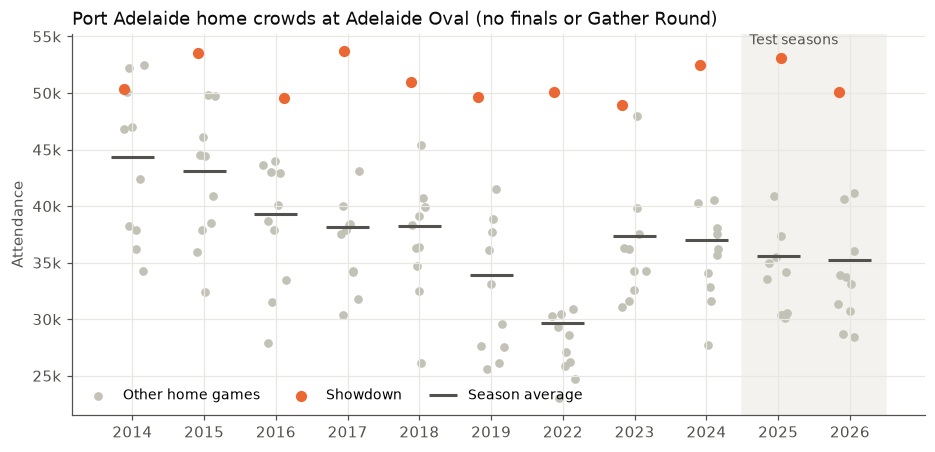

season,2014,2015,2016,2017,2018,2019,2022,2023,2024,2025,2026
season average,44364.0,43086.0,39332.0,38136.0,38227.0,33950.0,29693.0,37336.0,36999.0,35556.0,35263.0


In [2]:
fig, ax = plt.subplots(figsize=(10, 4.5))
seasons = TRAIN + TEST
x_of = {s: i for i, s in enumerate(seasons)}
x = games["season"].map(x_of) + np.random.default_rng(SEED).uniform(-0.18, 0.18, len(games))
other = ~games["showdown"]
ax.scatter(x[other], games.loc[other, "attendance"], s=22, color=GREY, label="Other home games")
ax.scatter(x[~other], games.loc[~other, "attendance"], s=40, color=ORANGE, zorder=3, label="Showdown")
means = games.groupby("season")["attendance"].mean()
ax.hlines(means.values, [x_of[s] - 0.3 for s in means.index], [x_of[s] + 0.3 for s in means.index],
          color=INK, linewidth=2, label="Season average")
ax.axvspan(len(TRAIN) - 0.5, len(seasons) - 0.5, color="#f3f2ee", zorder=0)
ax.annotate("Test seasons", (len(TRAIN) - 0.4, 1.0), xycoords=("data", "axes fraction"),
            va="top", fontsize=9, color=INK)
ax.set_xticks(range(len(seasons)), seasons)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_ylabel("Attendance")
ax.set_title("Port Adelaide home crowds at Adelaide Oval (no finals or Gather Round)",
             loc="left", color=TITLE)
ax.legend(frameon=False, loc="lower left", ncol=3, fontsize=9)
plt.show()
means.round(0).to_frame("season average").T

## 2. What the training seasons show

Training seasons only (2014–2024). Showdowns are left out of these two charts
because they'd swamp everything else.

Training Showdowns: 9, average 51,034; other games: 90, average 36,589
Correlation of recent form with crowd (non-Showdowns): 0.15


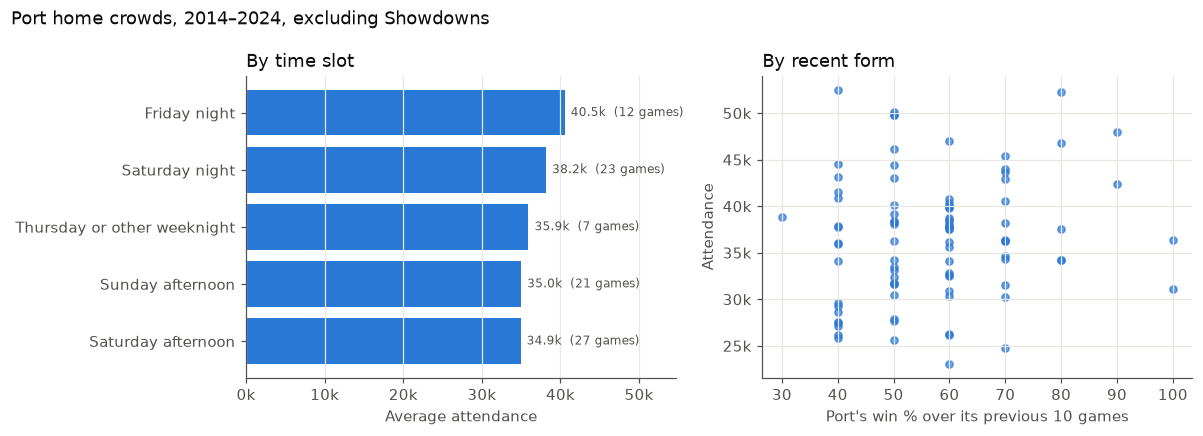

,size,mean
slot,,
Saturday afternoon,27,34920.0
Sunday afternoon,21,34984.0
Thursday or other weeknight,7,35925.0
Saturday night,23,38160.0
Friday night,12,40533.0


In [3]:
plain = train[~train["showdown"]]
print(f"Training Showdowns: {train['showdown'].sum()}, average {train.loc[train['showdown'], 'attendance'].mean():,.0f}; "
      f"other games: {len(plain)}, average {plain['attendance'].mean():,.0f}")
by_slot = plain.groupby("slot")["attendance"].agg(["size", "mean"]).sort_values("mean")
print(f"Correlation of recent form with crowd (non-Showdowns): {plain[['form', 'attendance']].corr().iloc[0, 1]:.2f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1]})
left.barh(by_slot.index, by_slot["mean"], color=BLUE)
for i, (slot, row) in enumerate(by_slot.iterrows()):
    left.annotate(f"{row['mean'] / 1000:.1f}k  ({row['size']:.0f} games)", (row["mean"], i),
                  xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
left.set_xlim(0, by_slot["mean"].max() * 1.35)
left.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
left.set_xlabel("Average attendance")
left.set_title("By time slot", loc="left", color=TITLE)
left.grid(axis="y", visible=False)

right.scatter(plain["form"], plain["attendance"], s=22, color=BLUE, alpha=0.7)
right.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
right.set_xlabel("Port's win % over its previous 10 games")
right.set_ylabel("Attendance")
right.set_title("By recent form", loc="left", color=TITLE)
fig.suptitle("Port home crowds, 2014–2024, excluding Showdowns", x=0.01, ha="left", color=TITLE)
fig.tight_layout()
plt.show()
by_slot.round(0)

## 3. Choosing a model (training seasons only)

Four nested linear regressions, each adding one of the agreed predictors:

| model | predictors |
|---|---|
| Baseline | none: predict the training average for every game |
| A | Showdown |
| B | Showdown + time slot |
| C | Showdown + time slot + recent form |

The time slot enters as one yes/no column per slot, compared with Saturday
afternoon (the most common slot). **Leave-one-season-out cross-validation:**
fit on 8 training seasons, predict the 9th, and repeat for each season. A
model that only memorised the training data would do badly here.

In [4]:
MODELS = ["Baseline", "A", "B", "C"]
SLOTS = ["Saturday night", "Friday night", "Sunday afternoon", "Thursday or other weeknight"]  # vs Saturday afternoon


def features(df: pd.DataFrame, model: str) -> pd.DataFrame:
    """The columns each model uses, plus an intercept."""
    X = pd.DataFrame({"intercept": 1.0}, index=df.index)
    if model in ("A", "B", "C"):
        X["Showdown"] = df["showdown"] * 1.0
    if model in ("B", "C"):
        # No Sunday night games in training, so one would be treated as Sunday afternoon (see plan)
        slot = df["slot"].replace("Sunday night", "Sunday afternoon")
        for s in SLOTS:
            X[s] = (slot == s) * 1.0
    if model == "C":
        X["form"] = df["form"]
    return X


def fit(df: pd.DataFrame, model: str) -> pd.Series:
    """Ordinary least squares coefficients."""
    X = features(df, model)
    coef, *_ = np.linalg.lstsq(X.to_numpy(), df["attendance"].to_numpy(), rcond=None)
    return pd.Series(coef, index=X.columns)


def predict(coef: pd.Series, df: pd.DataFrame, model: str) -> pd.Series:
    return features(df, model) @ coef


cv = []
for season in TRAIN:
    fold_train, fold_test = train[train["season"] != season], train[train["season"] == season]
    for model in MODELS:
        error = predict(fit(fold_train, model), fold_test, model) - fold_test["attendance"]
        cv.append(pd.DataFrame({"season": season, "model": model, "error": error}))
cv = pd.concat(cv)
cv["abs_error"] = cv["error"].abs()

cv_mae = cv.groupby("model")["abs_error"].mean().reindex(MODELS)
CHOSEN = cv_mae.drop("Baseline").idxmin()
print(f"Chosen model (lowest cross-validated MAE): {CHOSEN}")
cv_mae.round(0).to_frame("cross-validated MAE")

Chosen model (lowest cross-validated MAE): A


,cross-validated MAE
model,
Baseline,6296.0
A,5217.0
B,5236.0
C,5255.0


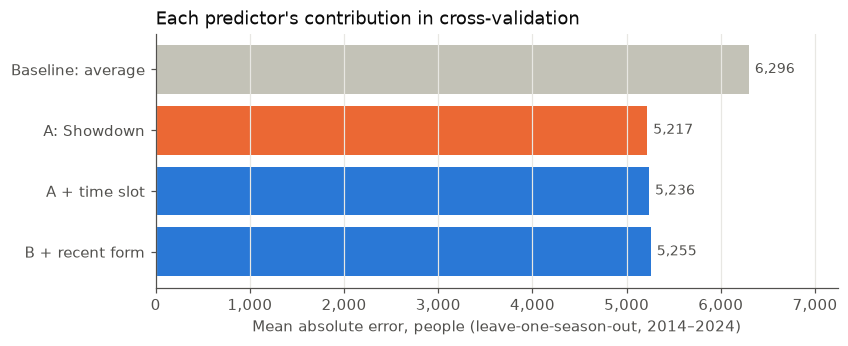

model,Baseline,A,B,C,A: mean error (bias)
season,,,,,
2014,7942.0,7661.0,7629.0,7347.0,-7269.0
2015,6940.0,6463.0,6646.0,7616.0,-5832.0
2016,5293.0,4862.0,5055.0,4762.0,-1608.0
2017,4135.0,3141.0,2866.0,3088.0,-262.0
2018,4607.0,3422.0,2992.0,2821.0,-365.0
2019,7156.0,5682.0,6491.0,6041.0,4447.0
2022,11265.0,9235.0,9362.0,9030.0,9235.0
2023,4795.0,3450.0,3444.0,4178.0,638.0
2024,4533.0,3039.0,2641.0,2411.0,1017.0


In [5]:
fig, ax = plt.subplots(figsize=(8, 3))
colours = [GREY if m == "Baseline" else ORANGE if m == CHOSEN else BLUE for m in MODELS]
names = {"Baseline": "Baseline: average", "A": "A: Showdown", "B": "A + time slot", "C": "B + recent form"}
y = np.arange(len(MODELS))[::-1]
ax.barh(y, cv_mae.values, color=colours)
for yi, value in zip(y, cv_mae.values):
    ax.annotate(f"{value:,.0f}", (value, yi), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_yticks(y, [names[m] for m in MODELS])
ax.set_xlim(0, cv_mae.max() * 1.15)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_xlabel("Mean absolute error, people (leave-one-season-out, 2014–2024)")
ax.set_title("Each predictor's contribution in cross-validation", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
plt.show()

# Where the errors come from: each held-out season's average error (positive = predicted too high)
by_season = cv.pivot_table(index="season", columns="model", values="abs_error", aggfunc="mean")[MODELS].round(0)
by_season[f"{CHOSEN}: mean error (bias)"] = cv[cv["model"] == CHOSEN].groupby("season")["error"].mean().round(0)
by_season

## 4. The chosen model, fitted on all training seasons

Coefficients are in people. Slot coefficients are relative to a Saturday afternoon
game, and form is per 10 percentage points (one extra win in the last 10).

In [6]:
coef = {model: fit(train, model) for model in MODELS}
shown = coef[CHOSEN].copy()
if "form" in shown:
    shown["form"] *= 10
shown = shown.rename({"intercept": "Intercept (non-Showdown Saturday afternoon"
                      + (", 0% form)" if "form" in shown else ")"),
                      "form": "Per extra win in the last 10"})
shown.round(0).to_frame(f"model {CHOSEN}")

,model A
Intercept (non-Showdown Saturday afternoon),36589.0
Showdown,14445.0


## 5. The test: 2025 and 2026

The baseline and the chosen model, both fitted on all 99 training games, predict the
22 home games of 2025 and 2026. These seasons weren't used for any choice above.
The 95% interval for the improvement resamples the 22 test games (2,000 resamples).

In [7]:
for model in MODELS:
    test[f"pred_{model}"] = predict(coef[model], test, model)
    test[f"abs_{model}"] = (test[f"pred_{model}"] - test["attendance"]).abs()

improvement, low, high = bootstrap(test, lambda d: d["abs_Baseline"].mean() - d[f"abs_{CHOSEN}"].mean(),
                                   n=N_BOOT, seed=SEED)
print(f"Test MAE: baseline {test['abs_Baseline'].mean():,.0f}, model {CHOSEN} {test[f'abs_{CHOSEN}'].mean():,.0f}")
print(f"Improvement: {improvement:,.0f} people (95% CI {low:,.0f} to {high:,.0f})")
print(f"Share of test games where model {CHOSEN} beat the baseline: "
      f"{(test[f'abs_{CHOSEN}'] < test['abs_Baseline']).mean():.0%}")

summary = pd.DataFrame({
    "all 22 games": test[[f"abs_{m}" for m in MODELS]].mean(),
    "Showdowns": test.loc[test["showdown"], [f"abs_{m}" for m in MODELS]].mean(),
    "other games": test.loc[~test["showdown"], [f"abs_{m}" for m in MODELS]].mean(),
}).set_axis(MODELS)
print(f"Test Showdowns: {test['showdown'].sum()}; slots: {test['slot'].value_counts().to_dict()}")
normal = test[~test["showdown"]]
print(f"Non-Showdown test games: average crowd {normal['attendance'].mean():,.0f}; "
      f"model {CHOSEN} over-predicted {(normal[f'pred_{CHOSEN}'] > normal['attendance']).sum()} of {len(normal)}")
misses = (test[f"pred_{CHOSEN}"] - test["attendance"]).abs().sort_values(ascending=False).head(2)
for i, miss in misses.items():
    print(f"  Big miss: {test.at[i, 'label']}: actual {test.at[i, 'attendance']:,.0f}, off by {miss:,.0f}")
summary.round(0)

Test MAE: baseline 5,798, model A 3,923
Improvement: 1,875 people (95% CI 648 to 3,535)
Share of test games where model A beat the baseline: 82%
Test Showdowns: 2; slots: {'Saturday night': 8, 'Sunday afternoon': 6, 'Saturday afternoon': 5, 'Friday night': 2, 'Thursday or other weeknight': 1}
Non-Showdown test games: average crowd 33,790; model A over-predicted 16 of 20
  Big miss: 2026 R24 v Melbourne: actual 28,417, off by 8,172
  Big miss: 2026 R20 v Fremantle: actual 28,727, off by 7,862


,all 22 games,Showdowns,other games
Baseline,5798.0,13699.0,5008.0
A,3923.0,1515.0,4164.0
B,3533.0,1515.0,3735.0
C,3063.0,725.0,3296.0


## 6. Exploratory: one regression with five variables

A second linear regression, suggested after the results above were in, so it's
**exploratory**: the 2025–2026 games had already been scored once. Same training
seasons (2014–2024) and test seasons (2025–2026), same MAE.

| variable | coding |
|---|---|
| Day | one-hot: **Thu/Fri** and **Sunday**, each compared with Saturday. (Thursdays and any other weekday join Friday, since all are night games.) |
| Night | yes if the game starts at **6pm or later** (Adelaide time) |
| Showdown | yes for Port v Adelaide |
| Gather Round | yes for Port's home game in Gather Round. These games are now **included**: 2 in training, 2 in the test |
| Form | Port's win % over its previous 10 games (entered per extra win, i.e. per 10 points) |

Because day and night are separate, a Sunday night game gets the Sunday effect
plus the night effect, even though training has no Sunday night games.

In [8]:
# The same home games as before, plus Port's home Gather Round games
games5 = matches[is_home].copy()
games5["gather"] = is_gather[is_home]
games5["showdown"] = games5["away"] == "Adelaide"
day = games5["start"].dt.day_name()
games5["day"] = day.where(day.isin(["Saturday", "Sunday"]), "Thu/Fri")
games5["night"] = games5["start"].dt.hour >= 18
games5["label"] = (games5["season"].astype(str) + " R" + games5["round"].str.removeprefix("Round ")
                   + " v " + games5["away"] + np.where(games5["gather"], " (Gather)", ""))
games5 = games5.sort_values("start").reset_index(drop=True)
train5 = games5[games5["season"].isin(TRAIN)].copy()
test5 = games5[games5["season"].isin(TEST)].copy()

print(f"Training games: {len(train5)} (Gather Round: {train5['gather'].sum()}), "
      f"test games: {len(test5)} (Gather Round: {test5['gather'].sum()})")
print("Weekdays grouped into Thu/Fri:", sorted(day[~day.isin(['Saturday', 'Sunday'])].unique()))
print("Training games by day and night:")
pd.crosstab(train5["day"], train5["night"].map({True: "night (6pm+)", False: "day"}))

Training games: 101 (Gather Round: 2), test games: 24 (Gather Round: 2)
Weekdays grouped into Thu/Fri: ['Friday', 'Thursday']
Training games by day and night:


night,day,night (6pm+)
day,,
Saturday,29,30
Sunday,22,0
Thu/Fri,0,20


In [9]:
def features5(df: pd.DataFrame) -> pd.DataFrame:
    """Intercept, one-hot day (Saturday is the comparison) and the yes/no variables."""
    return pd.DataFrame({
        "intercept": 1.0,
        "Thu/Fri": (df["day"] == "Thu/Fri") * 1.0,
        "Sunday": (df["day"] == "Sunday") * 1.0,
        "Night (6pm+)": df["night"] * 1.0,
        "Showdown": df["showdown"] * 1.0,
        "Gather Round": df["gather"] * 1.0,
        "Form (per extra win)": df["form"] / 10,
    }, index=df.index)


def fit5(df: pd.DataFrame) -> pd.Series:
    """Ordinary least squares coefficients for the five-variable model."""
    X = features5(df)
    coef, *_ = np.linalg.lstsq(X.to_numpy(), df["attendance"].to_numpy(), rcond=None)
    return pd.Series(coef, index=X.columns)


def predict5(coef: pd.Series, df: pd.DataFrame) -> pd.Series:
    return features5(df) @ coef


coef5 = fit5(train5)
# 95% intervals: refit on 2,000 resamples of the training games
rng = np.random.default_rng(SEED)
boot5 = pd.DataFrame([fit5(train5.iloc[rng.integers(0, len(train5), len(train5))]) for _ in range(N_BOOT)])
table5 = pd.DataFrame({"coefficient": coef5, "low": boot5.quantile(0.025), "high": boot5.quantile(0.975)})
# With only 2 Gather Round games, many resamples contain none, so its interval means nothing
table5.loc["Gather Round", ["low", "high"]] = np.nan

print(f"Thu/Fri night vs Saturday afternoon: {coef5['Thu/Fri'] + coef5['Night (6pm+)']:+,.0f}")
print(f"Saturday night vs Saturday afternoon: {coef5['Night (6pm+)']:+,.0f}")
print(f"Sunday night vs Saturday afternoon: {coef5['Sunday'] + coef5['Night (6pm+)']:+,.0f}")
table5.round(0)

Thu/Fri night vs Saturday afternoon: +3,925
Saturday night vs Saturday afternoon: +2,702
Sunday night vs Saturday afternoon: +3,048


,coefficient,low,high
intercept,31208.0,24455.0,36876.0
Thu/Fri,1223.0,-3447.0,5586.0
Sunday,347.0,-2555.0,3140.0
Night (6pm+),2702.0,-468.0,5989.0
Showdown,14835.0,11533.0,17466.0
Gather Round,8799.0,NaN,NaN
Form (per extra win),660.0,-287.0,1752.0


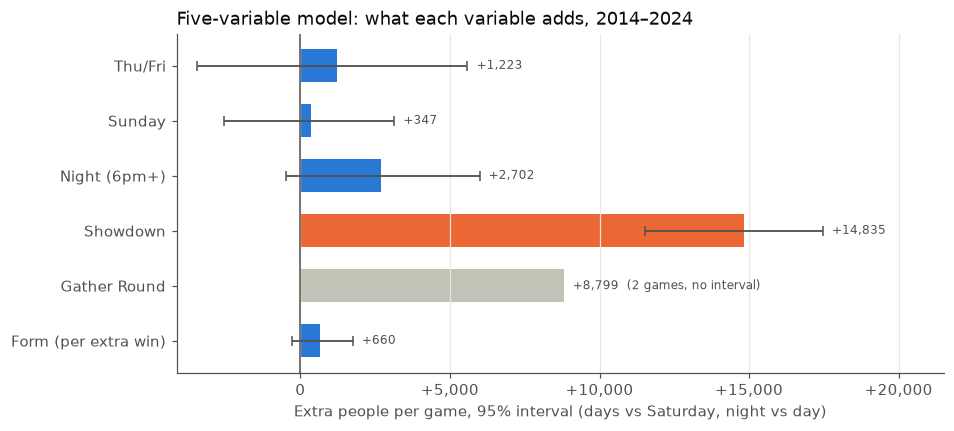

In [10]:
shown = table5.drop("intercept").iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(shown))
colours = [GREY if name == "Gather Round" else ORANGE if name == "Showdown" else BLUE for name in shown.index]
ax.barh(y, shown["coefficient"], color=colours, height=0.6)
has_ci = shown["low"].notna()
ax.errorbar(shown.loc[has_ci, "coefficient"], y[has_ci.to_numpy()],
            xerr=[shown.loc[has_ci, "coefficient"] - shown.loc[has_ci, "low"],
                  shown.loc[has_ci, "high"] - shown.loc[has_ci, "coefficient"]],
            fmt="none", ecolor=INK, elinewidth=1.2, capsize=3)
for yi, (name, row) in zip(y, shown.iterrows()):
    right = row["high"] if pd.notna(row["high"]) else row["coefficient"]
    note = f"{row['coefficient']:+,.0f}" + ("  (2 games, no interval)" if name == "Gather Round" else "")
    ax.annotate(note, (max(right, 0), yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, shown.index)
ax.set_xlim(min(-4000, shown["low"].min() * 1.2), shown["coefficient"].max() * 1.45)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+,.0f}" if v else "0")
ax.set_xlabel("Extra people per game, 95% interval (days vs Saturday, night vs day)")
ax.set_title("Five-variable model: what each variable adds, 2014–2024", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
plt.show()

In [11]:
# Cross-validation on the training seasons, with the baseline and model A refitted on the same games
cv5 = []
for season in TRAIN:
    fold_train, fold_test = train5[train5["season"] != season], train5[train5["season"] == season]
    cv5.append(pd.DataFrame({
        "Baseline": predict(fit(fold_train, "Baseline"), fold_test, "Baseline"),
        "A": predict(fit(fold_train, "A"), fold_test, "A"),
        "Five-variable": predict5(fit5(fold_train), fold_test),
    }).sub(fold_test["attendance"], axis=0).abs())
cv5 = pd.concat(cv5)

for name, model_coef in [("Baseline", fit(train5, "Baseline")), ("A", fit(train5, "A"))]:
    test5[f"pred_{name}"] = predict(model_coef, test5, name)
test5["pred_Five-variable"] = predict5(coef5, test5)
NAMES5 = ["Baseline", "A", "Five-variable"]
for name in NAMES5:
    test5[f"abs_{name}"] = (test5[f"pred_{name}"] - test5["attendance"]).abs()

normal5 = ~test5["gather"]
compare5 = pd.DataFrame({
    "cross-validated MAE (2014–2024)": cv5.mean(),
    "test MAE, all 24 games": [test5[f"abs_{n}"].mean() for n in NAMES5],
    "test MAE, 22 non-Gather games": [test5.loc[normal5, f"abs_{n}"].mean() for n in NAMES5],
}, index=NAMES5)

for other in ["Baseline", "A"]:
    gain, low, high = bootstrap(test5, lambda d: d[f"abs_{other}"].mean() - d["abs_Five-variable"].mean(),
                                n=N_BOOT, seed=SEED)
    print(f"Five-variable vs {other}, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
compare5.round(0)

Five-variable vs Baseline, test (24 games): 3,061 fewer people of error (95% CI 1,625 to 4,731)


Five-variable vs A, test (24 games): 1,470 fewer people of error (95% CI 478 to 2,630)


,cross-validated MAE (2014–2024),"test MAE, all 24 games","test MAE, 22 non-Gather games"
Baseline,6328.0,6183.0,5888.0
A,5287.0,4593.0,4038.0
Five-variable,5111.0,3122.0,3242.0


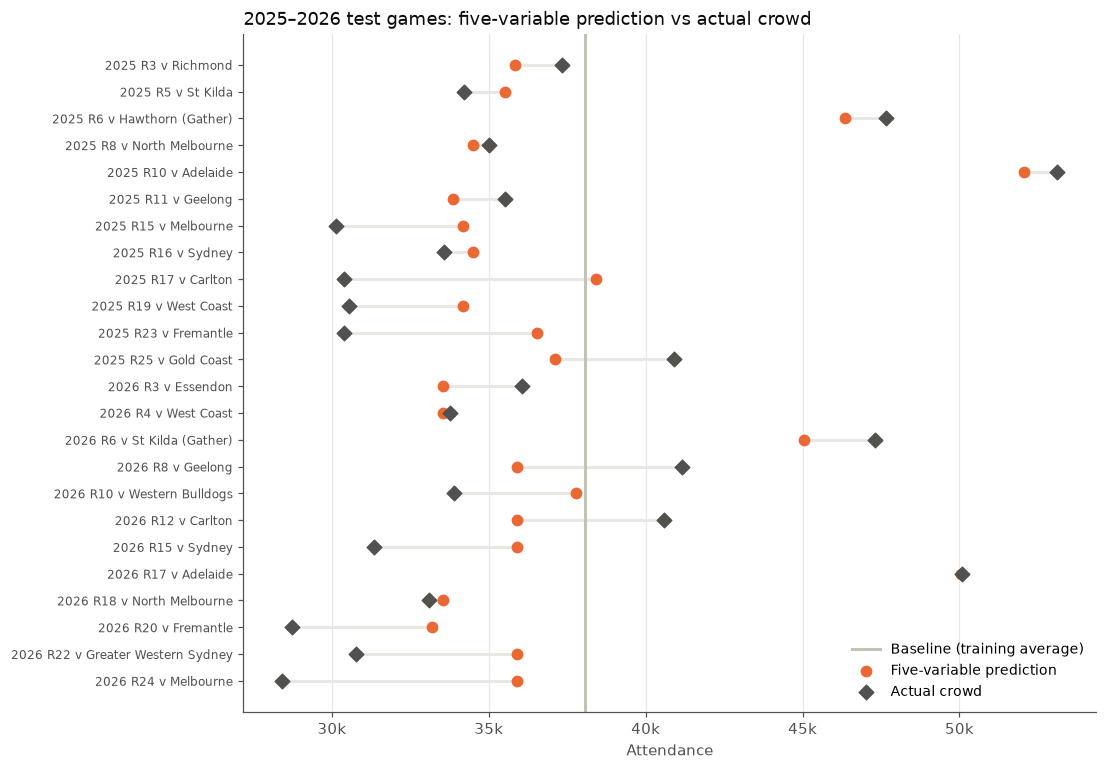

Big miss: 2025 R17 v Carlton: actual 30,381, predicted 38,431
Big miss: 2026 R24 v Melbourne: actual 28,417, predicted 35,888
Big miss: 2025 R23 v Fremantle: actual 30,390, predicted 36,548


,label,day,night,form,attendance,pred_A,pred_Five-variable
101,2025 R3 v Richmond,Saturday,False,70.0,37342.0,36800.0,35825.0
102,2025 R5 v St Kilda,Sunday,False,60.0,34201.0,36800.0,35512.0
103,2025 R6 v Hawthorn (Gather),Sunday,True,50.0,47671.0,36800.0,46353.0
104,2025 R8 v North Melbourne,Saturday,False,50.0,35004.0,36800.0,34506.0
105,2025 R10 v Adelaide,Saturday,True,50.0,53117.0,51034.0,52043.0
106,2025 R11 v Geelong,Saturday,False,40.0,35508.0,36800.0,33846.0
107,2025 R15 v Melbourne,Sunday,False,40.0,30144.0,36800.0,34193.0
108,2025 R16 v Sydney,Saturday,False,50.0,33576.0,36800.0,34506.0
109,2025 R17 v Carlton,Thu/Fri,True,50.0,30381.0,36800.0,38431.0
110,2025 R19 v West Coast,Sunday,False,40.0,30553.0,36800.0,34193.0


In [12]:
fig, ax = plt.subplots(figsize=(10, 8))
ordered = test5.sort_values("start")
y = np.arange(len(ordered))[::-1]
ax.axvline(fit(train5, "Baseline")["intercept"], color=GREY, linewidth=2, label="Baseline (training average)")
ax.hlines(y, ordered["pred_Five-variable"], ordered["attendance"], color="#e8e7e3", linewidth=2, zorder=1)
ax.scatter(ordered["pred_Five-variable"], y, s=45, color=ORANGE, zorder=3, label="Five-variable prediction")
ax.scatter(ordered["attendance"], y, s=45, color=INK, marker="D", zorder=3, label="Actual crowd")
ax.set_yticks(y, ordered["label"], fontsize=8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Attendance")
ax.set_title("2025–2026 test games: five-variable prediction vs actual crowd", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

misses5 = (test5["pred_Five-variable"] - test5["attendance"]).abs().sort_values(ascending=False).head(3)
for i, miss in misses5.items():
    print(f"Big miss: {test5.at[i, 'label']}: actual {test5.at[i, 'attendance']:,.0f}, "
          f"predicted {test5.at[i, 'pred_Five-variable']:,.0f}")
ordered[["label", "day", "night", "form", "attendance", "pred_A", "pred_Five-variable"]].round(0)

## 7. Exploratory: predicting the next game with everything known so far

The question now is: **given everything known before a game, including the crowds
at Port's earlier home games, how many will turn up?** Each variable has a footy
reason, and the list was fixed before this model was fitted:

| variable | reason |
|---|---|
| Day, night, Showdown, Gather Round, form | as in section 6 |
| **Early season** | yes for Port's first 3 home games of a season. Interest is highest at the start. |
| **Recent crowd level** | the average **surprise** (actual crowd minus the section 6 model's prediction, refitted with the early-season flag) over Port's **last 5 normal home games**, leaving out Showdowns and Gather Round. If interest has dropped and recent crowds are down, they'll likely stay down. |
| **Capacity cap** | no prediction above **53,698**, the biggest crowd in training (Adelaide Oval holds about 53,500). |

That's **9 fitted numbers** (an intercept and 8 coefficients) from 101 training
games. The window of 5 games was fixed in advance, not tuned.

**How the recent level is built, in two steps:**
1. Fit the model without the recent level, then work out each game's surprise.
2. For each game, average the surprises of the previous 5 normal home games
   (running across seasons, so round 1 uses the end of last season), then refit
   with that average as one more variable.

**No peeking:** in cross-validation, step 1 is fitted without the held-out season.
Within the held-out season, each game only sees crowds from *earlier* games, just
as it would in real life.

In [13]:
CAP = train5["attendance"].max()
WINDOW = 5
games5["early"] = games5.groupby("season").cumcount() < 3  # games5 is in date order
games5["normal"] = ~games5["showdown"] & ~games5["gather"]
for df in (train5, test5):
    df[["early", "normal"]] = games5.loc[df.index, ["early", "normal"]]
print(f"Capacity cap: {CAP:,.0f}; early-season games in training: "
      f"{games5.loc[games5['season'].isin(TRAIN), 'early'].sum()}")


def features7(df: pd.DataFrame, level: pd.Series | None = None) -> pd.DataFrame:
    """The section 6 variables plus the early-season flag and, optionally, the recent level."""
    X = features5(df)
    X["Early season (first 3)"] = df["early"] * 1.0
    if level is not None:
        X["Recent crowd level"] = level.loc[df.index]
    return X


def ols(X: pd.DataFrame, y: pd.Series) -> pd.Series:
    coef, *_ = np.linalg.lstsq(X.to_numpy(), y.to_numpy(), rcond=None)
    return pd.Series(coef, index=X.columns)


def recent_level(base_coef: pd.Series, features=features7) -> pd.Series:
    """For every game in games5: the mean surprise of Port's previous WINDOW normal home games.

    The surprise is the actual crowd minus the step 1 prediction. Only games before
    each game count (0 before the first normal game). Note that 2020-21 aren't in the
    data, so early 2022 uses the end of 2019.
    """
    surprise = games5["attendance"] - features(games5) @ base_coef
    rolling = surprise[games5["normal"]].rolling(WINDOW, min_periods=1).mean()
    # Carry each normal game's running level forward, then shift so a game never sees itself
    return rolling.reindex(games5.index).ffill().shift(1).fillna(0)


def fit7(train_df: pd.DataFrame, features=features7) -> tuple[pd.Series, pd.Series]:
    """Steps 1 and 2 on train_df. Returns (coefficients, recent level for every game).

    features: the column builder, so a later section can add variables to both steps.
    """
    base = ols(features(train_df), train_df["attendance"])
    level = recent_level(base, features)
    return ols(features(train_df, level), train_df["attendance"]), level


def predict7(coef: pd.Series, level: pd.Series, df: pd.DataFrame, features=features7) -> pd.Series:
    return np.minimum(features(df, level) @ coef, CAP)


coef7, level7 = fit7(train5)
# 95% intervals: refit step 2 on 2,000 resamples of the training games (the recent level is held fixed)
rng = np.random.default_rng(SEED)
X7 = features7(train5, level7)
boot7 = pd.DataFrame([ols(X7.iloc[idx], train5["attendance"].iloc[idx])
                      for idx in (rng.integers(0, len(train5), len(train5)) for _ in range(N_BOOT))])
table7 = pd.DataFrame({"coefficient": coef7, "low": boot7.quantile(0.025), "high": boot7.quantile(0.975)})
table7.loc["Gather Round", ["low", "high"]] = np.nan  # only 2 training games
# Show the recent level per 1,000 people of surprise, so it reads like the others
shown7 = table7.copy()
shown7.loc["Recent crowd level"] *= 1000
shown7 = shown7.rename(index={"Recent crowd level": "Recent level (per 1,000 surprise)"})
shown7.round(0)

Capacity cap: 53,698; early-season games in training: 27


,coefficient,low,high
intercept,30607.0,25143.0,35335.0
Thu/Fri,1092.0,-2274.0,4541.0
Sunday,-347.0,-2719.0,2021.0
Night (6pm+),2241.0,-276.0,4643.0
Showdown,15384.0,13125.0,17906.0
Gather Round,8964.0,NaN,NaN
Form (per extra win),685.0,-34.0,1567.0
Early season (first 3),3059.0,686.0,5469.0
"Recent level (per 1,000 surprise)",778.0,578.0,1000.0


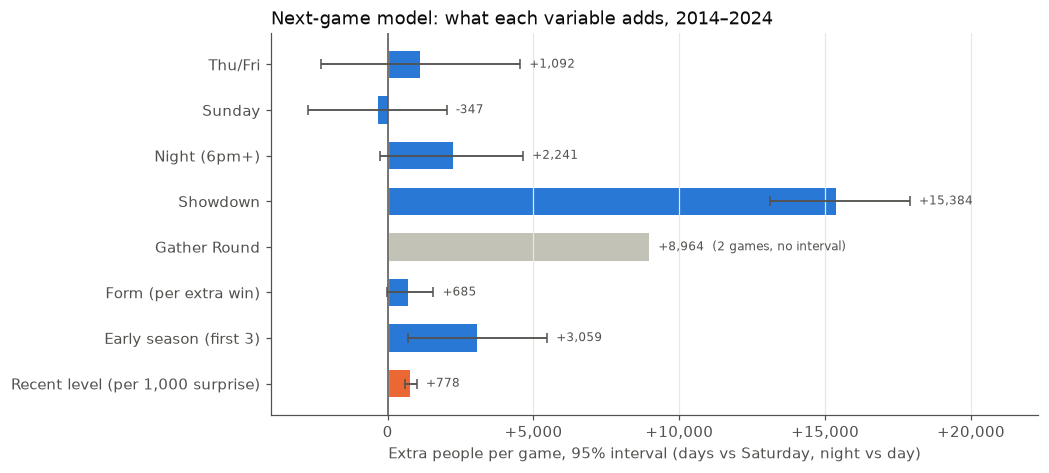

In [14]:
shown = shown7.drop("intercept").iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(shown))
colours = [GREY if name == "Gather Round" else ORANGE if name.startswith("Recent") else BLUE for name in shown.index]
ax.barh(y, shown["coefficient"], color=colours, height=0.6)
has_ci = shown["low"].notna()
ax.errorbar(shown.loc[has_ci, "coefficient"], y[has_ci.to_numpy()],
            xerr=[shown.loc[has_ci, "coefficient"] - shown.loc[has_ci, "low"],
                  shown.loc[has_ci, "high"] - shown.loc[has_ci, "coefficient"]],
            fmt="none", ecolor=INK, elinewidth=1.2, capsize=3)
for yi, (name, row) in zip(y, shown.iterrows()):
    right = row["high"] if pd.notna(row["high"]) else row["coefficient"]
    note = f"{row['coefficient']:+,.0f}" + ("  (2 games, no interval)" if name == "Gather Round" else "")
    ax.annotate(note, (max(right, 0), yi), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(y, shown.index)
ax.set_xlim(min(-4000, shown["low"].min() * 1.2), shown["coefficient"].max() * 1.45)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+,.0f}" if v else "0")
ax.set_xlabel("Extra people per game, 95% interval (days vs Saturday, night vs day)")
ax.set_title("Next-game model: what each variable adds, 2014–2024", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
plt.show()

In [15]:
# Leave-one-season-out, as before. Levels for training games just after the held-out
# season use that season's crowds, as they would in real time.
cv7 = []
for season in TRAIN:
    fold_train, fold_test = train5[train5["season"] != season], train5[train5["season"] == season]
    fold_coef, fold_level = fit7(fold_train)
    cv7.append(pd.DataFrame({
        "season": season, "label": fold_test["label"], "attendance": fold_test["attendance"],
        "Five-variable": predict5(fit5(fold_train), fold_test),
        "Next-game": predict7(fold_coef, fold_level, fold_test),
    }))
cv7 = pd.concat(cv7)

test5["pred_Next-game"] = predict7(coef7, level7, test5)
test5["abs_Next-game"] = (test5["pred_Next-game"] - test5["attendance"]).abs()
NAMES7 = ["Baseline", "A", "Five-variable", "Next-game"]
compare7 = pd.DataFrame({
    "cross-validated MAE (2014–2024)": [cv5["Baseline"].mean(), cv5["A"].mean(),
                                        (cv7["Five-variable"] - cv7["attendance"]).abs().mean(),
                                        (cv7["Next-game"] - cv7["attendance"]).abs().mean()],
    "test MAE, all 24 games": [test5[f"abs_{n}"].mean() for n in NAMES7],
    "test MAE, 22 non-Gather games": [test5.loc[normal5, f"abs_{n}"].mean() for n in NAMES7],
}, index=NAMES7)

for other in ["Baseline", "Five-variable"]:
    gain, low, high = bootstrap(test5, lambda d: d[f"abs_{other}"].mean() - d["abs_Next-game"].mean(),
                                n=N_BOOT, seed=SEED)
    print(f"Next-game vs {other}, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
print(f"Predictions hitting the cap: {(cv7['Next-game'] >= CAP).sum()} in cross-validation, "
      f"{(test5['pred_Next-game'] >= CAP).sum()} in the test")
compare7.round(0)

Next-game vs Baseline, test (24 games): 3,055 fewer people of error (95% CI 1,362 to 4,773)


Next-game vs Five-variable, test (24 games): -6 fewer people of error (95% CI -689 to 601)
Predictions hitting the cap: 3 in cross-validation, 0 in the test


,cross-validated MAE (2014–2024),"test MAE, all 24 games","test MAE, 22 non-Gather games"
Baseline,6328.0,6183.0,5888.0
A,5287.0,4593.0,4038.0
Five-variable,5111.0,3122.0,3242.0
Next-game,3916.0,3129.0,3253.0


### How the recent level handles a bad season: 2022

2022 was the worst season for every model above. Here it's held out of the
training data (cross-validation), so the model has to work it out game by game.

2022 MAE: five-variable 9,184, next-game 4,881


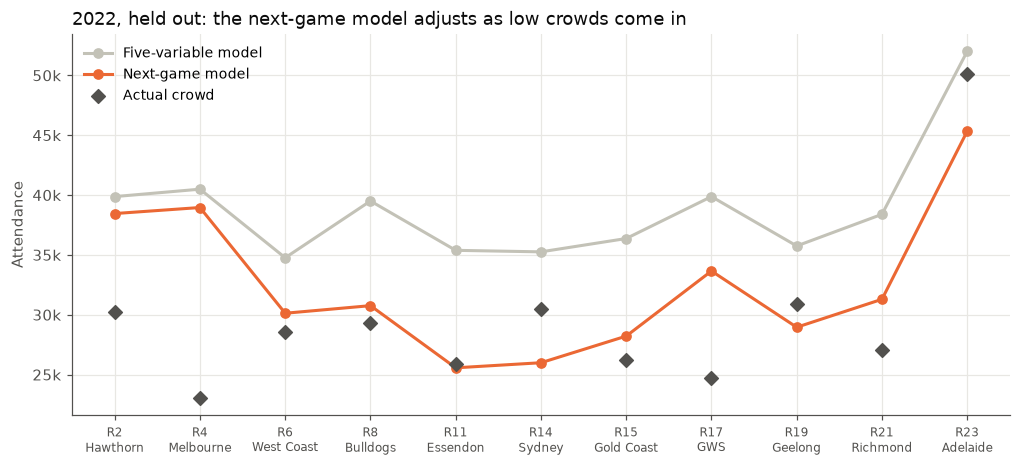

,season,label,attendance,Five-variable,Next-game
0,2022,2022 R2 v Hawthorn,30267.0,39871.0,38455.0
1,2022,2022 R4 v Melbourne,23058.0,40491.0,38959.0
2,2022,2022 R6 v West Coast,28587.0,34762.0,30128.0
3,2022,2022 R8 v Western Bulldogs,29290.0,39505.0,30761.0
4,2022,2022 R11 v Essendon,25877.0,35383.0,25568.0
5,2022,2022 R14 v Sydney,30445.0,35255.0,25993.0
6,2022,2022 R15 v Gold Coast,26241.0,36369.0,28217.0
7,2022,2022 R17 v Greater Western Sydney,24744.0,39871.0,33655.0
8,2022,2022 R19 v Geelong,30937.0,35749.0,28958.0
9,2022,2022 R21 v Richmond,27091.0,38391.0,31293.0


In [16]:
season22 = cv7[cv7["season"] == 2022].reset_index(drop=True)
print(f"2022 MAE: five-variable {(season22['Five-variable'] - season22['attendance']).abs().mean():,.0f}, "
      f"next-game {(season22['Next-game'] - season22['attendance']).abs().mean():,.0f}")

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(season22))
SHORT = {"Greater Western Sydney": "GWS", "Western Bulldogs": "Bulldogs"}
ax.plot(x, season22["Five-variable"], color=GREY, linewidth=2, marker="o", label="Five-variable model")
ax.plot(x, season22["Next-game"], color=ORANGE, linewidth=2, marker="o", label="Next-game model")
ax.scatter(x, season22["attendance"], color=INK, marker="D", s=40, zorder=3, label="Actual crowd")
ticks = season22["label"].str.removeprefix("2022 ").replace(SHORT, regex=True).str.replace(" v ", "\n", regex=False)
ax.set_xticks(x, ticks, fontsize=8)
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_ylabel("Attendance")
ax.set_title("2022, held out: the next-game model adjusts as low crowds come in", loc="left", color=TITLE)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.show()
season22.round(0)

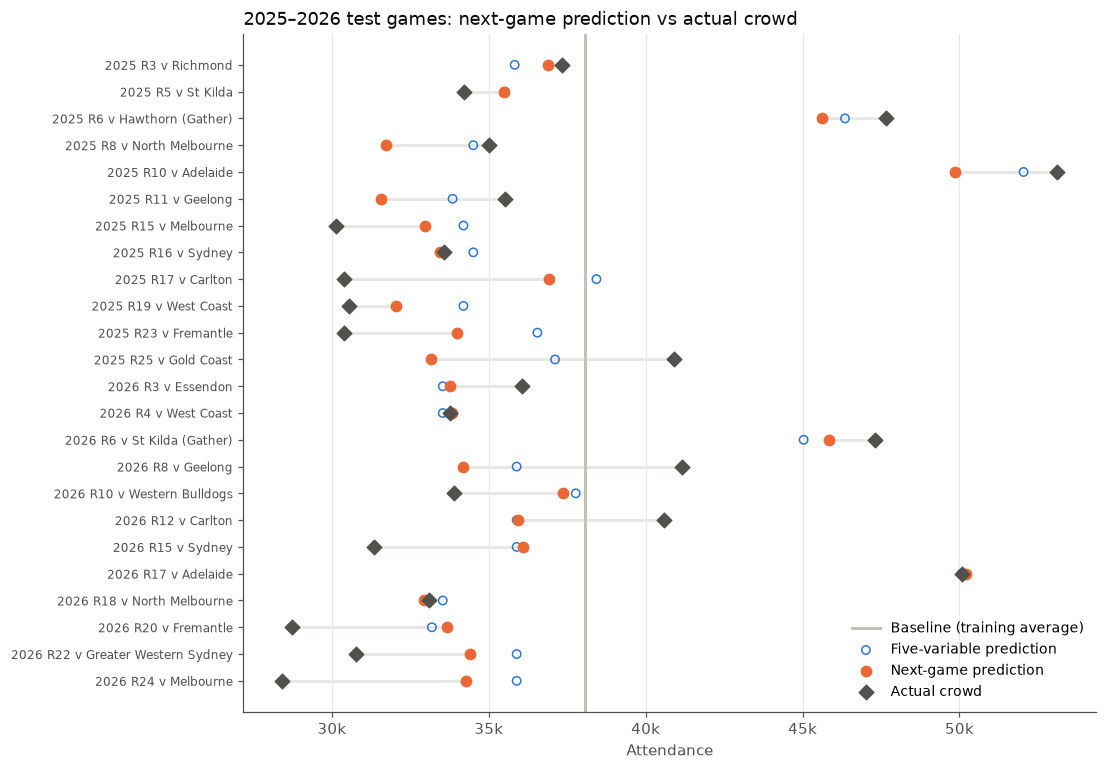

Big miss: 2025 R25 v Gold Coast: actual 40,897, predicted 33,157
Big miss: 2026 R8 v Geelong: actual 41,164, predicted 34,163
Big miss: 2025 R17 v Carlton: actual 30,381, predicted 36,934


,label,attendance,pred_Five-variable,pred_Next-game,level
101,2025 R3 v Richmond,37342.0,35825.0,36879.0,-2036.0
102,2025 R5 v St Kilda,34201.0,35512.0,35490.0,-2495.0
103,2025 R6 v Hawthorn (Gather),47671.0,46353.0,45632.0,-2980.0
104,2025 R8 v North Melbourne,35004.0,34506.0,31714.0,-2980.0
105,2025 R10 v Adelaide,53117.0,52043.0,49871.0,-2297.0
106,2025 R11 v Geelong,35508.0,33846.0,31560.0,-2297.0
107,2025 R15 v Melbourne,30144.0,34193.0,32973.0,-37.0
108,2025 R16 v Sydney,33576.0,34506.0,33442.0,-759.0
109,2025 R17 v Carlton,30381.0,38431.0,36934.0,-556.0
110,2025 R19 v West Coast,30553.0,34193.0,32038.0,-1238.0


In [17]:
fig, ax = plt.subplots(figsize=(10, 8))
ordered = test5.sort_values("start")
y = np.arange(len(ordered))[::-1]
ax.axvline(fit(train5, "Baseline")["intercept"], color=GREY, linewidth=2, label="Baseline (training average)")
ax.hlines(y, ordered["pred_Next-game"], ordered["attendance"], color="#e8e7e3", linewidth=2, zorder=1)
ax.scatter(ordered["pred_Five-variable"], y, s=30, facecolors="none", edgecolors=BLUE, zorder=2,
           label="Five-variable prediction")
ax.scatter(ordered["pred_Next-game"], y, s=45, color=ORANGE, zorder=3, label="Next-game prediction")
ax.scatter(ordered["attendance"], y, s=45, color=INK, marker="D", zorder=3, label="Actual crowd")
ax.set_yticks(y, ordered["label"], fontsize=8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Attendance")
ax.set_title("2025–2026 test games: next-game prediction vs actual crowd", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()

misses7 = (test5["pred_Next-game"] - test5["attendance"]).abs().sort_values(ascending=False).head(3)
for i, miss in misses7.items():
    print(f"Big miss: {test5.at[i, 'label']}: actual {test5.at[i, 'attendance']:,.0f}, "
          f"predicted {test5.at[i, 'pred_Next-game']:,.0f}")
ordered[["label", "attendance", "pred_Five-variable", "pred_Next-game"]].assign(
    level=level7.loc[ordered.index]).round(0)

### Variant: Showdowns as an exception

Showdowns sell out whatever Port's form or recent crowds. So this variant
**predicts every Showdown at the median training Showdown crowd**, and fits the
next-game model on **non-Showdown games only**, so Showdowns don't affect its other
coefficients. In cross-validation the median comes from the fold's training seasons.
This change was made after seeing section 7's results, so it's exploratory too.

In [18]:
def fit_rule(train_df: pd.DataFrame, features=features7) -> tuple[pd.Series, pd.Series, float]:
    """Next-game model fitted without Showdowns, plus the median Showdown crowd."""
    coef, level = fit7(train_df[~train_df["showdown"]], features)  # the Showdown column is then all 0, coefficient 0
    return coef, level, train_df.loc[train_df["showdown"], "attendance"].median()


def predict_rule(coef: pd.Series, level: pd.Series, showdown_pred: float, df: pd.DataFrame,
                 features=features7) -> pd.Series:
    return predict7(coef, level, df, features).where(~df["showdown"], showdown_pred)


rule = fit_rule(train5)
print(f"Showdown prediction (training median): {rule[2]:,.0f}")

cv7["Showdown rule"] = pd.concat([
    predict_rule(*fit_rule(train5[train5["season"] != season]), train5[train5["season"] == season])
    for season in TRAIN])
test5["pred_Showdown rule"] = predict_rule(*rule, test5)
test5["abs_Showdown rule"] = (test5["pred_Showdown rule"] - test5["attendance"]).abs()


def mae(pred, actual, mask=None):
    error = (pred - actual).abs()
    return error.mean() if mask is None else error[mask].mean()


sd_cv, sd_test = train5["showdown"].loc[cv7.index], test5["showdown"]
compare_rule = pd.DataFrame({
    name: {
        "CV MAE, all": mae(cv7[col], cv7["attendance"]),
        "CV MAE, Showdowns": mae(cv7[col], cv7["attendance"], sd_cv),
        "CV MAE, other games": mae(cv7[col], cv7["attendance"], ~sd_cv),
        "CV MAE, 2022": mae(cv7[col], cv7["attendance"], cv7["season"] == 2022),
        "test MAE, all 24": test5[f"abs_{col}"].mean(),
        "test MAE, Showdowns": test5.loc[sd_test, f"abs_{col}"].mean(),
        "test MAE, other games": test5.loc[~sd_test, f"abs_{col}"].mean(),
    }
    for name, col in [("Next-game", "Next-game"), ("Next-game + Showdown rule", "Showdown rule")]
}).T

gain, low, high = bootstrap(test5, lambda d: d["abs_Next-game"].mean() - d["abs_Showdown rule"].mean(),
                            n=N_BOOT, seed=SEED)
print(f"Showdown rule vs next-game, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
for i in test5.index[sd_test]:
    print(f"  {test5.at[i, 'label']}: actual {test5.at[i, 'attendance']:,.0f}, next-game "
          f"{test5.at[i, 'pred_Next-game']:,.0f}, Showdown rule {test5.at[i, 'pred_Showdown rule']:,.0f}")
compare_rule.round(0)

Showdown prediction (training median): 50,397


Showdown rule vs next-game, test (24 games): 13 fewer people of error (95% CI -53 to 82)
  2025 R10 v Adelaide: actual 53,117, next-game 49,871, Showdown rule 50,397
  2026 R17 v Adelaide: actual 50,087, next-game 50,221, Showdown rule 50,397


,"CV MAE, all","CV MAE, Showdowns","CV MAE, other games","CV MAE, 2022","test MAE, all 24","test MAE, Showdowns","test MAE, other games"
Next-game,3916.0,1944.0,4109.0,4881.0,3129.0,1690.0,3259.0
Next-game + Showdown rule,3919.0,1584.0,4148.0,4627.0,3115.0,1515.0,3261.0


In [19]:
# The non-Showdown model's coefficients, next to the section 7 model's
both = pd.DataFrame({"section 7": coef7, "without Showdowns": rule[0]})
both.loc["Recent crowd level"] *= 1000  # per 1,000 people of surprise, as in the chart
both.drop("Showdown").round(0)

,section 7,without Showdowns
intercept,30607.0,30567.0
Thu/Fri,1092.0,1247.0
Sunday,-347.0,-419.0
Night (6pm+),2241.0,2008.0
Gather Round,8964.0,9006.0
Form (per extra win),685.0,702.0
Early season (first 3),3059.0,3210.0
Recent crowd level,778.0,801.0


### Adding the opposition's drawing power

Big clubs bring travelling fans and wider interest. Opponents are grouped into three
tiers by supporter base, fixed before fitting (not ranked by Port's own crowds):

| tier | clubs |
|---|---|
| **Top** | Collingwood, Richmond, Essendon, Carlton, Hawthorn, Geelong |
| **Middle** | Brisbane, Western Bulldogs, Melbourne, Sydney, West Coast, Fremantle |
| **Bottom** | St Kilda, North Melbourne, Gold Coast, GWS |

The tier enters as two one-hot columns (top and bottom, each compared with middle)
in both steps of the next-game model with the Showdown rule, so a run of big-club
opponents doesn't inflate the recent level. Adelaide needs no tier: Showdowns are
predicted by the rule. Exploratory, like the rest of section 7.

In [20]:
TOP_TIER = ["Collingwood", "Richmond", "Essendon", "Carlton", "Hawthorn", "Geelong"]
BOTTOM_TIER = ["St Kilda", "North Melbourne", "Gold Coast", "Greater Western Sydney"]
games5["tier"] = np.select([games5["away"].isin(TOP_TIER), games5["away"].isin(BOTTOM_TIER)],
                           ["Top", "Bottom"], "Middle")
for df in (train5, test5):
    df["tier"] = games5.loc[df.index, "tier"]


def features_tier(df: pd.DataFrame, level: pd.Series | None = None) -> pd.DataFrame:
    """The next-game variables plus opposition tier (top and bottom vs middle)."""
    X = features7(df, level)
    X["Top-tier opponent"] = (df["tier"] == "Top") * 1.0
    X["Bottom-tier opponent"] = (df["tier"] == "Bottom") * 1.0
    return X


plain_games = train5[train5["normal"]]
by_tier = plain_games.groupby("tier")["attendance"].agg(["size", "mean"]).reindex(["Top", "Middle", "Bottom"])
print("Training games by tier (Showdowns aside):",
      train5[~train5["showdown"]].groupby("tier").size().reindex(["Top", "Middle", "Bottom"]).to_dict(),
      "| test:", test5[~test5["showdown"]].groupby("tier").size().reindex(["Top", "Middle", "Bottom"]).to_dict())

rule_tier = fit_rule(train5, features_tier)
# 95% intervals for the tier effects: refit step 2 on resamples of the non-Showdown training games (level held fixed)
no_sd = train5[~train5["showdown"]]
X_tier = features_tier(no_sd, rule_tier[1])
rng = np.random.default_rng(SEED)
boot_tier = pd.DataFrame([ols(X_tier.iloc[idx], no_sd["attendance"].iloc[idx])
                          for idx in (rng.integers(0, len(no_sd), len(no_sd)) for _ in range(N_BOOT))])
for name in ["Top-tier opponent", "Bottom-tier opponent"]:
    print(f"{name}: {rule_tier[0][name]:+,.0f} vs a middle-tier opponent "
          f"(95% CI {boot_tier[name].quantile(0.025):+,.0f} to {boot_tier[name].quantile(0.975):+,.0f})")

cv7["Tier"] = pd.concat([
    predict_rule(*fit_rule(train5[train5["season"] != season], features_tier),
                 train5[train5["season"] == season], features_tier)
    for season in TRAIN])
test5["pred_Tier"] = predict_rule(*rule_tier, test5, features_tier)
test5["abs_Tier"] = (test5["pred_Tier"] - test5["attendance"]).abs()

compare_tier = pd.DataFrame({
    name: {
        "CV MAE, all": mae(cv7[col], cv7["attendance"]),
        "CV MAE, other games": mae(cv7[col], cv7["attendance"], ~sd_cv),
        "test MAE, all 24": test5[f"abs_{col}"].mean(),
        "test MAE, other games": test5.loc[~sd_test, f"abs_{col}"].mean(),
    }
    for name, col in [("Next-game + Showdown rule", "Showdown rule"), ("+ opposition tier", "Tier")]
}).T
gain, low, high = bootstrap(test5, lambda d: d["abs_Showdown rule"].mean() - d["abs_Tier"].mean(),
                            n=N_BOOT, seed=SEED)
print(f"Adding tier, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
compare_tier.round(0)

Training games by tier (Showdowns aside): {'Top': 35, 'Middle': 39, 'Bottom': 18} | test: {'Top': 7, 'Middle': 9, 'Bottom': 6}


Top-tier opponent: +3,825 vs a middle-tier opponent (95% CI +1,317 to +6,502)
Bottom-tier opponent: -2,082 vs a middle-tier opponent (95% CI -4,559 to +403)


Adding tier, test (24 games): 201 fewer people of error (95% CI -683 to 1,048)


,"CV MAE, all","CV MAE, other games","test MAE, all 24","test MAE, other games"
Next-game + Showdown rule,3919.0,4148.0,3115.0,3261.0
+ opposition tier,3621.0,3820.0,2914.0,3041.0


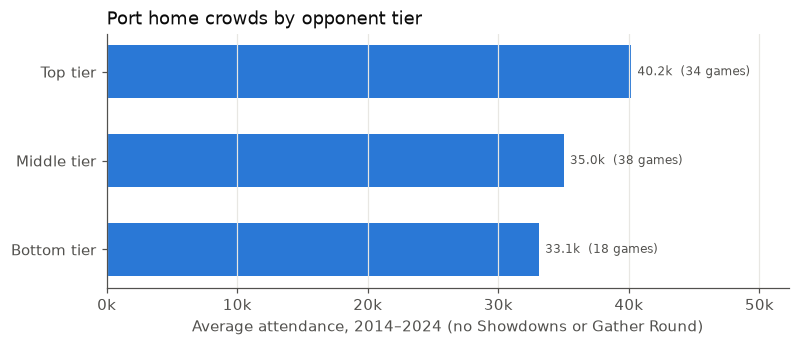

,size,mean
tier,,
Top,34,40187.0
Middle,38,35016.0
Bottom,18,33116.0


In [21]:
fig, ax = plt.subplots(figsize=(8, 3))
y = np.arange(len(by_tier))[::-1]
ax.barh(y, by_tier["mean"], color=BLUE, height=0.6)
for yi, (tier, row) in zip(y, by_tier.iterrows()):
    ax.annotate(f"{row['mean'] / 1000:.1f}k  ({row['size']:.0f} games)", (row["mean"], yi),
                xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
ax.set_yticks(y, [f"{tier} tier" for tier in by_tier.index])
ax.set_xlim(0, by_tier["mean"].max() * 1.3)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Average attendance, 2014–2024 (no Showdowns or Gather Round)")
ax.set_title("Port home crowds by opponent tier", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
plt.show()
by_tier.round(0)

### Adding the weather: wet or dry

Rain keeps casual fans at home. Daily rainfall comes from the Bureau of
Meteorology's **Adelaide Airport** station (023034), an automatic station about
7 km from Adelaide Oval (`src/afl/weather.py`). The airport was chosen over the
North Adelaide gauge, which is read by hand and misses many weekend readings.

- **Wet:** 1mm or more of rain from **9am on game day to 9am the next day**. BOM
  credits rain to the morning it's measured, so this is the next day's reading.
- It's actual rain, not the forecast people decided on, and rain after the final
  siren counts too, so it's a blurry measure.
- The wet flag joins the model with the Showdown rule and opposition tier, in both
  steps. Showdowns stay at the fixed Showdown prediction. Exploratory, like the
  rest of section 7.

In [22]:
from afl.weather import daily_rainfall, game_day_rain

games5["rain_mm"] = game_day_rain(games5["start"], daily_rainfall())
games5["wet"] = games5["rain_mm"] >= 1
for df in (train5, test5):
    df[["rain_mm", "wet"]] = games5.loc[df.index, ["rain_mm", "wet"]]
print(f"Games without a usable reading: {games5['rain_mm'].isna().sum()}; wet games: "
      f"{train5['wet'].sum()} of {len(train5)} in training, {test5['wet'].sum()} of {len(test5)} in the test")
print("Wet training games that were Showdowns:", train5.loc[train5["wet"], "showdown"].sum())


def features_wet(df: pd.DataFrame, level: pd.Series | None = None) -> pd.DataFrame:
    """The opposition-tier model's variables plus wet (see the threshold where `wet` is set)."""
    X = features_tier(df, level)
    X["Wet"] = df["wet"] * 1.0
    return X


rule_wet = fit_rule(train5, features_wet)
no_sd = train5[~train5["showdown"]]  # again, now with the wet column
X_wet = features_wet(no_sd, rule_wet[1])
rng = np.random.default_rng(SEED)
boot_wet = pd.DataFrame([ols(X_wet.iloc[idx], no_sd["attendance"].iloc[idx])
                         for idx in (rng.integers(0, len(no_sd), len(no_sd)) for _ in range(N_BOOT))])
print(f"Wet: {rule_wet[0]['Wet']:+,.0f} vs a dry game "
      f"(95% CI {boot_wet['Wet'].quantile(0.025):+,.0f} to {boot_wet['Wet'].quantile(0.975):+,.0f})")

raw_wet = train5[train5["normal"]].groupby("wet")["attendance"].agg(["size", "mean"]).rename(index={False: "dry", True: "wet"})
print("Raw averages, training normal games:", {k: f"{v:,.0f} ({n:.0f} games)" for k, n, v in raw_wet.itertuples()})

cv7["Wet"] = pd.concat([
    predict_rule(*fit_rule(train5[train5["season"] != season], features_wet),
                 train5[train5["season"] == season], features_wet)
    for season in TRAIN])
test5["pred_Wet"] = predict_rule(*rule_wet, test5, features_wet)
test5["abs_Wet"] = (test5["pred_Wet"] - test5["attendance"]).abs()

wet_cv = train5["wet"].loc[cv7.index]
compare_wet = pd.DataFrame({
    name: {
        "CV MAE, all": mae(cv7[col], cv7["attendance"]),
        "CV MAE, wet games": mae(cv7[col], cv7["attendance"], wet_cv),
        "test MAE, all 24": test5[f"abs_{col}"].mean(),
        "test MAE, wet games": test5.loc[test5["wet"], f"abs_{col}"].mean(),
    }
    for name, col in [("+ opposition tier", "Tier"), ("+ tier + wet", "Wet")]
}).T
gain, low, high = bootstrap(test5, lambda d: d["abs_Tier"].mean() - d["abs_Wet"].mean(), n=N_BOOT, seed=SEED)
print(f"Adding wet, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
compare_wet.round(0)

Games without a usable reading: 0; wet games: 21 of 101 in training, 3 of 24 in the test
Wet training games that were Showdowns: 1


Wet: -1,734 vs a dry game (95% CI -4,294 to +495)
Raw averages, training normal games: {'dry': '37,243 (71 games)', 'wet': '34,146 (19 games)'}


Adding wet, test (24 games): -146 fewer people of error (95% CI -410 to 102)


,"CV MAE, all","CV MAE, wet games","test MAE, all 24","test MAE, wet games"
+ opposition tier,3621.0,4590.0,2914.0,2769.0
+ tier + wet,3695.0,4774.0,3060.0,3511.0


**A heavier-rain threshold: 4mm.** Tried after seeing the 1mm result, so it's a
sensitivity check. Both thresholds are reported, and a better 4mm result could
partly be luck.

In [23]:
def wet_model(threshold: float) -> dict:
    """Refit the tier + wet model with 'wet' meaning at least `threshold` mm; return its key numbers."""
    for df in (games5, train5, test5):
        df["wet"] = df["rain_mm"] >= threshold
    rule_t = fit_rule(train5, features_wet)
    no_sd_t = train5[~train5["showdown"]]
    X_t = features_wet(no_sd_t, rule_t[1])
    rng = np.random.default_rng(SEED)
    boot_t = [ols(X_t.iloc[idx], no_sd_t["attendance"].iloc[idx])["Wet"]
              for idx in (rng.integers(0, len(no_sd_t), len(no_sd_t)) for _ in range(N_BOOT))]
    cv_pred = pd.concat([
        predict_rule(*fit_rule(train5[train5["season"] != season], features_wet),
                     train5[train5["season"] == season], features_wet)
        for season in TRAIN])
    test_abs = (predict_rule(*rule_t, test5, features_wet) - test5["attendance"]).abs()
    return {
        "wet training games": int(train5["wet"].sum()),
        "wet test games": int(test5["wet"].sum()),
        "wet effect": rule_t[0]["Wet"],
        "low": np.percentile(boot_t, 2.5),
        "high": np.percentile(boot_t, 97.5),
        "CV MAE": mae(cv_pred, cv7["attendance"]),
        "test MAE": test_abs.mean(),
    }


thresholds = pd.DataFrame({f"{t}mm": wet_model(t) for t in [1, 4]}).T
thresholds.loc["no wet flag"] = {"CV MAE": mae(cv7["Tier"], cv7["attendance"]), "test MAE": test5["abs_Tier"].mean()}
for df in (games5, train5, test5):  # put the 1mm flag back, as used above
    df["wet"] = df["rain_mm"] >= 1
thresholds.round(0)

,wet training games,wet test games,wet effect,low,high,CV MAE,test MAE
1mm,21.0,3.0,-1734.0,-4294.0,495.0,3695.0,3060.0
4mm,11.0,1.0,-1950.0,-6885.0,2819.0,3668.0,2849.0
no wet flag,NaN,NaN,NaN,NaN,NaN,3621.0,2914.0


## 8. The final model

The final model is the **next-game model with the Showdown rule, opposition tier and
wet weather (1mm or more)**. Rain stays in on footy logic: wet days keep casual fans
home. The data points that way (−1,734 people) but is too thin to prove it helps
predictions, since cross-validated error is about 70 people a game higher with rain
than without. That small cost is accepted in exchange for a model that makes footy
sense.

**How it predicts a game:**
- **Showdown:** the median training Showdown crowd, whatever else is going on.
- **Any other game:** start from the intercept, add each variable's effect below,
  and cap the result at 53,698.

In [24]:
final_coef, final_level, final_showdown = rule_wet
final = pd.DataFrame({"effect": final_coef, "low": boot_wet.quantile(0.025), "high": boot_wet.quantile(0.975)})
final = final.drop("Showdown")  # Showdowns use the rule instead
final.loc["Gather Round", ["low", "high"]] = np.nan  # only 2 training games
final.loc["Recent crowd level"] *= 1000
final = final.rename(index={"intercept": "Start: Saturday afternoon, middle-tier opponent, dry, 0% form",
                            "Recent crowd level": "Recent level (per 1,000 surprise)"})
print(f"Showdowns: {final_showdown:,.0f}; cap: {CAP:,.0f}")
print(f"Accuracy: cross-validated MAE {mae(cv7['Wet'], cv7['attendance']):,.0f}, "
      f"test MAE {test5['abs_Wet'].mean():,.0f} (baseline {test5['abs_Baseline'].mean():,.0f})")
final.round(0)

Showdowns: 50,397; cap: 53,698
Accuracy: cross-validated MAE 3,695, test MAE 3,060 (baseline 6,183)


,effect,low,high
"Start: Saturday afternoon, middle-tier opponent, dry, 0% form",30495.0,25605.0,35128.0
Thu/Fri,162.0,-3406.0,4041.0
Sunday,-661.0,-2661.0,1381.0
Night (6pm+),1032.0,-1847.0,3703.0
Gather Round,10596.0,NaN,NaN
Form (per extra win),780.0,10.0,1571.0
Early season (first 3),2006.0,-345.0,4426.0
"Recent level (per 1,000 surprise)",817.0,622.0,1052.0
Top-tier opponent,3797.0,1299.0,6521.0
Bottom-tier opponent,-2115.0,-4546.0,345.0


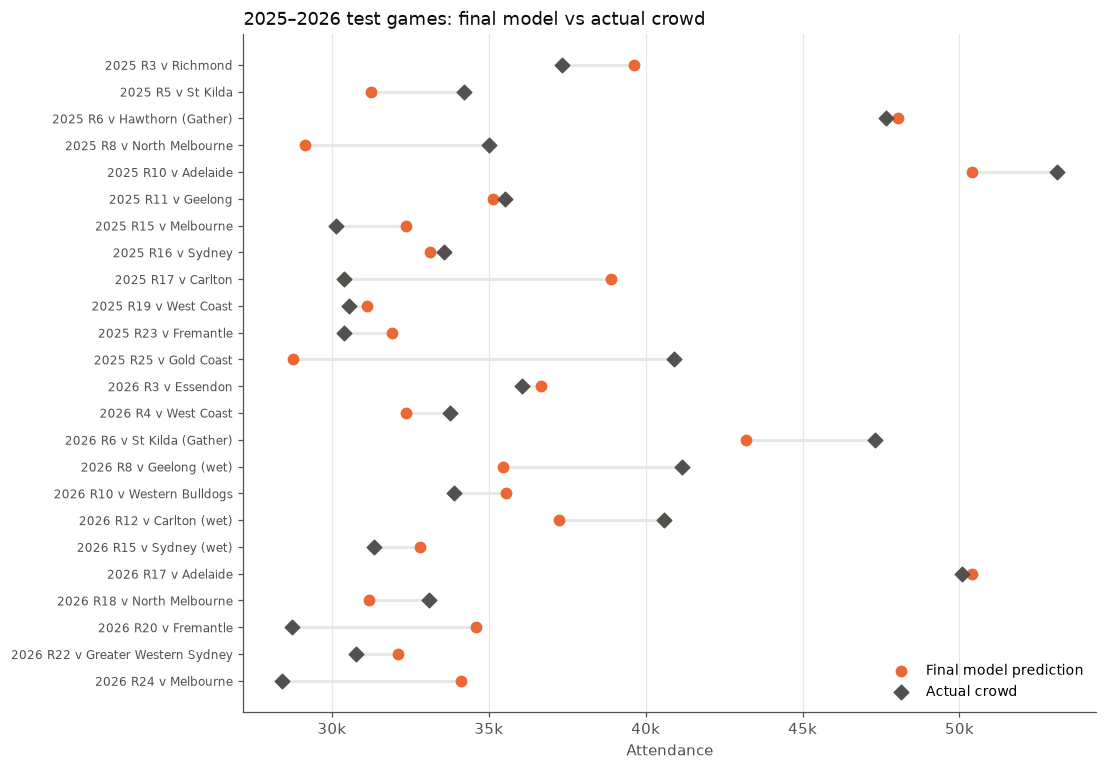

Test games predicted within 3,000 people: 67%


In [25]:
fig, ax = plt.subplots(figsize=(10, 8))
ordered = test5.sort_values("start")
y = np.arange(len(ordered))[::-1]
ax.hlines(y, ordered["pred_Wet"], ordered["attendance"], color="#e8e7e3", linewidth=2, zorder=1)
ax.scatter(ordered["pred_Wet"], y, s=45, color=ORANGE, zorder=3, label="Final model prediction")
ax.scatter(ordered["attendance"], y, s=45, color=INK, marker="D", zorder=3, label="Actual crowd")
labels = ordered["label"] + np.where(ordered["wet"], " (wet)", "")
ax.set_yticks(y, labels, fontsize=8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Attendance")
ax.set_title("2025–2026 test games: final model vs actual crowd", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right", fontsize=9)
plt.show()
within = ((ordered["pred_Wet"] - ordered["attendance"]).abs() <= 3000).mean()
print(f"Test games predicted within 3,000 people: {within:.0%}")

## 9. Exploratory: opponent form, and pooling Adelaide's home games

Two more ideas, each compared with the final model (section 8) on Port's games:

1. **Opponent form:** the opponent's win % over its previous 10 games, entered per
   extra win. A top-of-the-table opponent makes it a bigger game.
2. **Pooling Adelaide's home games.** The biggest limit so far has been sample size.
   Adelaide's home games at Adelaide Oval share the ground, the weather, the time
   slots and the opponents. So the model is fitted on **both clubs' home games**:
   - **Each club has its own base level** (an "Adelaide home game" flag), and form,
     early season and the recent crowd level come from each club's own games.
   - **Every effect is shared:** night, tier, rain, form and the rest are learned
     from both clubs' games together.
   - **Showdowns** stay at 50,397, the median Port-home Showdown crowd.
   - **Scoring is on Port's games only**, with the same cross-validation and test.

Both were suggested after the final model was chosen, so they're exploratory.

In [26]:
from afl.attendance import both_teams_form

forms = matches[["start", "home", "away"]].join(both_teams_form(matches)).set_index(["start", "home", "away"])
keys5 = pd.MultiIndex.from_frame(games5[["start", "home", "away"]])
games5["opp_form"] = forms["away_form"].reindex(keys5).to_numpy()
for df in (train5, test5):
    df["opp_form"] = games5.loc[df.index, "opp_form"]
print("Missing opponent form:", games5["opp_form"].isna().sum())


def features_opp(df: pd.DataFrame, level: pd.Series | None = None) -> pd.DataFrame:
    """The final model's variables plus the opponent's form (per extra win in their last 10)."""
    X = features_wet(df, level)
    X["Opponent form (per extra win)"] = df["opp_form"] / 10
    return X


rule_opp = fit_rule(train5, features_opp)
no_sd = train5[~train5["showdown"]]
X_opp = features_opp(no_sd, rule_opp[1])
rng = np.random.default_rng(SEED)
boot_opp = pd.DataFrame([ols(X_opp.iloc[idx], no_sd["attendance"].iloc[idx])
                         for idx in (rng.integers(0, len(no_sd), len(no_sd)) for _ in range(N_BOOT))])
name = "Opponent form (per extra win)"
print(f"Opponent form: {rule_opp[0][name]:+,.0f} per extra win "
      f"(95% CI {boot_opp[name].quantile(0.025):+,.0f} to {boot_opp[name].quantile(0.975):+,.0f})")

cv7["Opp form"] = pd.concat([
    predict_rule(*fit_rule(train5[train5["season"] != season], features_opp),
                 train5[train5["season"] == season], features_opp)
    for season in TRAIN])
test5["pred_Opp form"] = predict_rule(*rule_opp, test5, features_opp)
test5["abs_Opp form"] = (test5["pred_Opp form"] - test5["attendance"]).abs()

Missing opponent form: 0


Opponent form: +454 per extra win (95% CI -116 to +1,060)


In [27]:
ADELAIDE = "Adelaide"
SA_CLUBS = [PORT, ADELAIDE]

# Both clubs' home games at Adelaide Oval, in the same seasons, with the same exclusions
in_pool = (matches["home"].isin(SA_CLUBS) & (matches["venue"] == "Adelaide Oval")
           & ~matches["final"] & matches["season"].isin(TRAIN + TEST))
pool = matches[in_pool].join(both_teams_form(matches)).copy()
pool["gather"] = is_gather[in_pool]
pool = pool.sort_values("start").reset_index(drop=True)
pool["club"] = pool["home"]
pool["showdown"] = pool["away"].isin(SA_CLUBS)
pool["normal"] = ~pool["showdown"] & ~pool["gather"]
day = pool["start"].dt.day_name()
pool["day"] = day.where(day.isin(["Saturday", "Sunday"]), "Thu/Fri")
pool["night"] = pool["start"].dt.hour >= 18
pool["form"] = pool["home_form"]  # the home club's own form
pool["opp_form"] = pool["away_form"]
pool["early"] = pool.groupby(["club", "season"]).cumcount() < 3
pool["tier"] = np.select([pool["away"].isin(TOP_TIER), pool["away"].isin(BOTTOM_TIER)], ["Top", "Bottom"], "Middle")
pool["rain_mm"] = game_day_rain(pool["start"], daily_rainfall())
pool["wet"] = pool["rain_mm"] >= 1  # a missing reading counts as dry
pool_train = pool[pool["season"].isin(TRAIN)]
print("Pooled training games by club:", pool_train.groupby("club").size().to_dict(),
      "| missing form or attendance:", int(pool[["form", "opp_form", "attendance"]].isna().sum().sum()))
no_rain = pool[pool["rain_mm"].isna()]
print("Games without a usable rain reading (counted as dry):",
      [f"{r.club} v {r.away}, {r.start:%d %b %Y}" for r in no_rain.itertuples()])

# Port's rows in the pool must match the Port-only data exactly
port_rows = pool[pool["club"] == PORT].set_index("start")
check = games5.set_index("start")[["attendance", "form", "opp_form", "wet", "early", "tier"]]
print("Port rows match the Port-only data:", port_rows[check.columns].equals(check))


def features_pool(df: pd.DataFrame, level: pd.Series | None = None) -> pd.DataFrame:
    """Opponent-form model's variables plus a base-level shift for Adelaide's home games."""
    X = features_opp(df, level)
    X["Adelaide home game"] = (df["club"] == ADELAIDE) * 1.0
    return X


def recent_level_pool(base_coef: pd.Series) -> pd.Series:
    """Like recent_level(), but each club's level comes from its own last WINDOW normal home games."""
    surprise = pool["attendance"] - features_pool(pool) @ base_coef
    level = pd.Series(0.0, index=pool.index)
    for club in SA_CLUBS:
        rows = pool.index[pool["club"] == club]
        normal = pool.loc[rows, "normal"]
        rolling = surprise.loc[rows][normal].rolling(WINDOW, min_periods=1).mean()
        level.loc[rows] = rolling.reindex(rows).ffill().shift(1).fillna(0).to_numpy()
    return level


def fit_pool(train_df: pd.DataFrame) -> tuple[pd.Series, pd.Series, float]:
    """Both steps on both clubs' non-Showdown games; Showdowns get the median Port-home Showdown."""
    no_sd = train_df[~train_df["showdown"]]
    base = ols(features_pool(no_sd), no_sd["attendance"])
    level = recent_level_pool(base)
    coef = ols(features_pool(no_sd, level), no_sd["attendance"])
    showdown_pred = train_df.loc[train_df["showdown"] & (train_df["club"] == PORT), "attendance"].median()
    return coef, level, showdown_pred


def predict_pool(coef, level, showdown_pred, df):
    return np.minimum(features_pool(df, level) @ coef, CAP).where(~df["showdown"], showdown_pred)


rule_pool = fit_pool(pool_train)
no_sd_pool = pool_train[~pool_train["showdown"]]
X_pool = features_pool(no_sd_pool, rule_pool[1])
rng = np.random.default_rng(SEED)
boot_pool = pd.DataFrame([ols(X_pool.iloc[idx], no_sd_pool["attendance"].iloc[idx])
                          for idx in (rng.integers(0, len(no_sd_pool), len(no_sd_pool)) for _ in range(N_BOOT))])

# Map pooled predictions for Port's games back onto the Port-only rows (Port has one home game per start time)
port_start = games5["start"]
pool_port = pool["club"] == PORT
cv7["Pooled"] = pd.concat([
    predict_pool(*fit_pool(pool_train[pool_train["season"] != season]),
                 pool[pool_port & (pool["season"] == season)])
    .set_axis(pool.loc[pool_port & (pool["season"] == season), "start"])
    for season in TRAIN]).reindex(port_start.loc[cv7.index]).to_numpy()
test5["pred_Pooled"] = (predict_pool(*rule_pool, pool[pool_port & pool["season"].isin(TEST)])
                        .set_axis(pool.loc[pool_port & pool["season"].isin(TEST), "start"])
                        .reindex(test5["start"]).to_numpy())
test5["abs_Pooled"] = (test5["pred_Pooled"] - test5["attendance"]).abs()
print("Missing pooled predictions:", int(cv7["Pooled"].isna().sum() + test5["pred_Pooled"].isna().sum()))

Pooled training games by club: {'Adelaide': 100, 'Port Adelaide': 101} | missing form or attendance: 0
Games without a usable rain reading (counted as dry): ['Adelaide v Brisbane Lions, 06 Jun 2025', 'Adelaide v St Kilda, 18 Apr 2026']
Port rows match the Port-only data: True


Missing pooled predictions: 0


In [28]:
# The effects side by side: final model, + opponent form, pooled (95% intervals for the last two)
EFFECTS = ["Top-tier opponent", "Bottom-tier opponent", "Wet", "Night (6pm+)", "Early season (first 3)",
           "Form (per extra win)", "Opponent form (per extra win)", "Recent crowd level", "Adelaide home game"]
side = pd.DataFrame({
    "final": final_coef.reindex(EFFECTS),
    "+ opp form": rule_opp[0].reindex(EFFECTS),
    "+ opp form CI": [f"{boot_opp[e].quantile(0.025):+,.0f} to {boot_opp[e].quantile(0.975):+,.0f}"
                      if e in boot_opp else "" for e in EFFECTS],
    "pooled": rule_pool[0].reindex(EFFECTS),
    "pooled CI": [f"{boot_pool[e].quantile(0.025):+,.0f} to {boot_pool[e].quantile(0.975):+,.0f}" for e in EFFECTS],
}, index=EFFECTS)
level_row = "Recent crowd level"
side.loc[level_row, ["final", "+ opp form", "pooled"]] *= 1000  # per 1,000 people of surprise
for col in ["+ opp form CI", "pooled CI"]:
    src = boot_opp if col.startswith("+") else boot_pool
    side.loc[level_row, col] = (f"{1000 * src[level_row].quantile(0.025):+,.0f} to "
                                f"{1000 * src[level_row].quantile(0.975):+,.0f}")
side = side.rename(index={level_row: "Recent level (per 1,000 surprise)"})
print(f"Training games used: Port-only models {len(no_sd)}, pooled {len(no_sd_pool)} (Showdowns aside)")
side.round(0)

Training games used: Port-only models 92, pooled 183 (Showdowns aside)


,final,+ opp form,+ opp form CI,pooled,pooled CI
Top-tier opponent,3797.0,3689.0,"+1,157 to +6,373",2905.0,"+1,213 to +4,719"
Bottom-tier opponent,-2115.0,-1748.0,"-4,221 to +697",-2242.0,"-3,705 to -736"
Wet,-1734.0,-1740.0,"-4,274 to +397",-1824.0,"-3,301 to -474"
Night (6pm+),1032.0,551.0,"-2,255 to +3,137",891.0,"-952 to +2,540"
Early season (first 3),2006.0,2267.0,"-359 to +4,946",1206.0,"-525 to +2,781"
Form (per extra win),780.0,662.0,"-66 to +1,444",1214.0,"+725 to +1,709"
Opponent form (per extra win),NaN,454.0,"-116 to +1,060",464.0,+134 to +791
"Recent level (per 1,000 surprise)",817.0,812.0,"+604 to +1,054",839.0,"+690 to +1,001"
Adelaide home game,NaN,NaN,,6679.0,"+5,495 to +8,019"


In [29]:
MODELS9 = [("Final model (section 8)", "Wet"), ("+ opponent form", "Opp form"), ("Pooled with Adelaide", "Pooled")]
compare9 = pd.DataFrame({
    name: {"CV MAE (Port games)": mae(cv7[col], cv7["attendance"]),
           "CV MAE, 2022": mae(cv7[col], cv7["attendance"], cv7["season"] == 2022),
           "test MAE (Port games)": test5[f"abs_{col}"].mean()}
    for name, col in MODELS9
}).T
for name, col in MODELS9[1:]:
    gain, low, high = bootstrap(test5, lambda d: d["abs_Wet"].mean() - d[f"abs_{col}"].mean(), n=N_BOOT, seed=SEED)
    print(f"{name} vs final model, test (24 games): {gain:,.0f} fewer people of error (95% CI {low:,.0f} to {high:,.0f})")
compare9.round(0)

+ opponent form vs final model, test (24 games): -162 fewer people of error (95% CI -667 to 316)


Pooled with Adelaide vs final model, test (24 games): -479 fewer people of error (95% CI -1,050 to 102)


,CV MAE (Port games),"CV MAE, 2022",test MAE (Port games)
Final model (section 8),3695.0,4623.0,3060.0
+ opponent form,3761.0,5193.0,3222.0
Pooled with Adelaide,3710.0,4337.0,3539.0


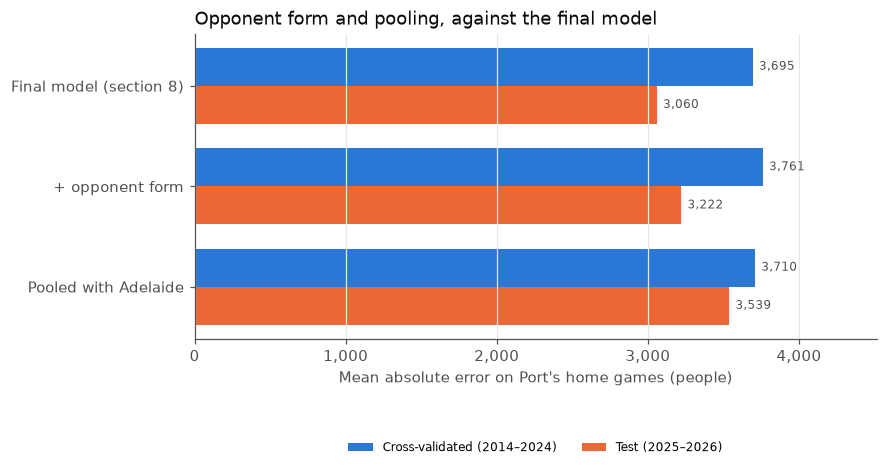

In [30]:
fig, ax = plt.subplots(figsize=(8, 3.6))
names = [name for name, _ in MODELS9]
y = np.arange(len(names))[::-1]
width = 0.38
cv_vals, test_vals = compare9["CV MAE (Port games)"], compare9["test MAE (Port games)"]
ax.barh(y + width / 2, cv_vals, height=width, color=BLUE, label="Cross-validated (2014–2024)")
ax.barh(y - width / 2, test_vals, height=width, color=ORANGE, label="Test (2025–2026)")
for yi, cv_v, test_v in zip(y, cv_vals, test_vals):
    ax.annotate(f"{cv_v:,.0f}", (cv_v, yi + width / 2), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
    ax.annotate(f"{test_v:,.0f}", (test_v, yi - width / 2), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK)
ax.set_yticks(y, names)
ax.set_xlim(0, max(cv_vals.max(), test_vals.max()) * 1.2)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.set_xlabel("Mean absolute error on Port's home games (people)")
ax.set_title("Opponent form and pooling, against the final model", loc="left", color=TITLE)
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.3), ncol=2, fontsize=8)
plt.show()

# Results

## Data

- **125 Port home games at Adelaide Oval** in 2014–2019 and 2022–2026, outside
  finals. **4 were in Gather Round** and are left out, leaving **121: 99 for training
  (11 a season, 2014–2024) and 22 for testing (2025–2026)**.
- In training, the **9 Showdowns averaged 51,034** and the other **90 games 36,589**.
  The season average fell from **44,364 in 2014** to **29,693 in 2022**, then
  recovered to about 37,000 in 2023–2024.

## The answer: the Showdown is the only predictor that clearly earns its place

- **Cross-validation (2014–2024):** predicting the average for every game misses by
  **6,296** people on average. Adding the Showdown flag (model A) cuts that to **5,217**.
  Adding time slot (**5,236**) and then recent form (**5,255**) made it very slightly
  *worse*, so **model A was chosen**, as the plan specified.
- **Model A is simply:** predict **36,589** for a normal home game and **51,034**
  (**+14,445**) for a Showdown.
- **On the unseen 2025–2026 games**, model A's MAE was **3,923**, against **5,798**
  for the baseline. That's **1,875 fewer people of error per game (95% CI 648 to
  3,535)**. It beat the baseline in **82%** of the 22 games. Most of the gain is
  the two Showdowns: an average miss of **1,515** against **13,699**. For other
  games, the MAE was **4,164** against **5,008**.

## Time slot and form: real patterns, but small and uncertain

- Night games did draw more in training. Friday nights averaged **40.5k** and
  Saturday nights **38.2k**, against **34.9k** for Saturday afternoons (excluding
  Showdowns). Recent form barely moved crowds (correlation **0.15**).
- But in cross-validation, neither improved predictions for a season the model
  hadn't seen. **On the test seasons they did help** (MAE **3,533** with slot,
  **3,063** with slot and form). That conflicts with cross-validation, and 22
  games is a small test, so the safe reading is "maybe a little", not "yes".

## Where the errors come from: whole seasons, not individual games

- Model A's biggest cross-validation misses are **season-wide**. It
  **over-predicted 2022 by 9,235 a game on average**, and under-predicted 2014 by
  **7,269** and 2015 by **5,832**. None of the three predictors captures a whole
  season being up or down.
- The test seasons show the same thing on a smaller scale. Normal home games
  averaged **33,790** in 2025–2026, about 2,800 below the training average, so
  model A over-predicted **16 of the 20** non-Showdown games. Its biggest misses
  were 2026 R24 v Melbourne (28,417, over by 8,172) and 2026 R20 v Fremantle
  (28,727, over by 7,862).

## Exploratory: the five-variable regression (section 6)

Suggested after the results above, so the test seasons had already been scored once.

- **Data:** the same games plus Port's home **Gather Round** games: **101 training
  games (2 Gather) and 24 test games (2 Gather)**. Thursdays are grouped with Fridays.
- **What each variable adds** (2014–2024, 95% intervals from 2,000 resamples):
  - **Showdown: +14,835** (11,533 to 17,466). The only clear effect.
  - **Gather Round: +8,799**, from just 2 training games, so no interval.
  - **Night (6pm+): +2,702** (−468 to 5,989).
  - **Thu/Fri: +1,223** on top of the night effect (−3,447 to 5,586). A Thursday or
    Friday night game comes out **+3,925** over a Saturday afternoon.
  - **Sunday: +347** (−2,555 to 3,140).
  - **Form: +660 per extra win in the last 10** (−287 to 1,752).
  - Night, day and form all point the expected way, but each interval includes 0.
- **Accuracy:** this is the best model so far in both checks.
  - **Cross-validated MAE:** **5,111**, against **5,287** for Showdown-only and **6,328**
    for the baseline (all on the same games).
  - **Test MAE on 2025–2026 (24 games):** **3,122**, against **4,593** for
    Showdown-only (**1,470 better, 95% CI 478 to 2,630**) and **6,183** for the baseline.
  - **Without the Gather Round games** it still wins: **3,242** against **4,038** for
    Showdown-only. (Section 5's model C did slightly better on those 22 games, 3,063.)
- **Biggest misses:** 2025 R17 v Carlton, a Thursday night (actual 30,381,
  predicted 38,431), and 2026 R24 v Melbourne (28,417, predicted 35,888).

## Exploratory: predicting the next game (section 7)

Adds an **early-season** flag (Port's first 3 home games) and the **recent crowd
level** (the average surprise over Port's last 5 normal home games) to section 6's
variables, with predictions capped at 53,698. Each game only uses crowds from
before it.

- **Both new variables are clear effects** (95% intervals exclude 0):
  - **Early season: +3,059** (686 to 5,469).
  - **Recent level: +778 for every 1,000 people** that recent crowds beat the model
    by (578 to 1,000). If the last 5 normal games came in 3,000 under, the next
    prediction drops by about 2,300.
  - **Showdown: +15,384**, **night: +2,241**, **form: +685 per extra win** (−34 to 1,567).
  - These intervals hold the recent level fixed, so they're a little too narrow.
- **Cross-validation (2014–2024):** MAE **3,916**, against **5,111** for the
  five-variable model, about a **quarter less error**. The gain comes from seasons
  that drifted. With 2022 held out, the model caught on to the low crowds within a
  couple of games, and its MAE for 2022 was **4,881**, against **9,184**.
- **Test (2025–2026): no gain.** MAE was **3,129**, against **3,122** for the
  five-variable model (difference 6 people, 95% CI −689 to 601), and **6,183** for
  the baseline. That fits section 6, where the five-variable model was only about
  1,000 a game off in each test season, so there was little drift to catch.
- **The capacity cap** changed 3 predictions in cross-validation and none in the test.
- **One weakness:** the recent level lowers Showdown predictions too, although
  Showdowns sell out regardless. The 2022 Showdown was predicted at **45,333**
  (actual **50,090**).
- **Variant, Showdowns as an exception:** predict every Showdown at the median
  training Showdown crowd (**50,397**), and fit the model on the other games only.
  - **Showdowns get better:** cross-validated MAE **1,584** against **1,944**, and
    **1,515** against **1,690** on the 2 test Showdowns.
  - **Other games get very slightly worse** (cross-validated **4,148** against
    **4,109**), so overall it's a wash: cross-validated **3,919** against **3,916**,
    and test **3,115** against **3,129** (13 fewer, 95% CI −53 to 82).
  - **The other coefficients barely move** (e.g. recent level +801 against +778 per 1,000).
  - It's still the more sensible design: it doesn't let a crowd slump drag down a
    sell-out, and it's easier to explain.
- **Adding the opposition tier** (top: Collingwood, Richmond, Essendon, Carlton,
  Hawthorn, Geelong; bottom: St Kilda, North Melbourne, Gold Coast, GWS):
  - **Raw averages** (2014–2024, no Showdowns or Gather Round): **40.2k** against
    top-tier opponents, **35.0k** middle and **33.1k** bottom.
  - **In the model: top tier +3,825** over a middle-tier opponent (95% CI +1,317
    to +6,502), a clear effect. **Bottom tier −2,082** (−4,559 to +403), probably
    real but not clear-cut.
  - **Cross-validated MAE 3,621**, against **3,919** without the tier, which is
    about 300 people better.
  - **Test MAE 2,914**, against **3,115** without the tier (201 fewer, 95% CI −683
    to 1,048). That's the lowest test error of any model here, though the
    interval includes 0.
- **Adding the weather** (wet if 1mm or more of rain at Adelaide Airport, 9am on game
  day to 9am the next day): **21 of 101 training games and 3 of 24 test games were wet.**
  - **Raw averages:** wet normal games drew **34,146** (19 games), against **37,243**
    for dry ones (71 games).
  - **In the model: −1,734** (95% CI −4,294 to +495). Much of the raw gap is explained
    by the other variables, e.g. wet games tend to fall mid-season.
  - **It doesn't help predictions:** cross-validated MAE **3,695** against **3,621**
    without it, and test MAE **3,060** against **2,914** (146 worse, 95% CI −410 to
    102). Even on wet games the cross-validated error got worse (4,774 against
    4,590). With about 20 wet games and a blurry measure (actual rain, not the
    forecast), the estimate is too noisy to improve predictions.
  - **A 4mm threshold** (tried after seeing the 1mm result): only **11 wet training
    games and 1 wet test game**. The effect is **−1,950** (95% CI −6,885 to +2,819).
    Cross-validated MAE **3,668**, still worse than **3,621** without the flag. Test
    MAE **2,849** against **2,914**, but that gain rests on a single wet test game.
  - **So the model with the opposition tier stays the best one.**
- **Biggest misses:** 2025 R25 v Gold Coast (40,897, predicted 33,157) and 2026
  R8 v Geelong (41,164, predicted 34,163). These are one-off big crowds, which a
  recent-level variable can't foresee.

## The final model (section 8)

The next-game model with the Showdown rule, opposition tier and wet weather (1mm+).
Rain is kept on footy logic, accepting a slightly higher cross-validated error.

- **Showdowns:** predicted at **50,397**. Every other game is capped at **53,698**.
- **Effects** (vs a dry Saturday afternoon game against a middle-tier opponent; 95% intervals):
  - **Top-tier opponent +3,797** (1,299 to 6,521).
  - **Bottom-tier opponent −2,115** (−4,546 to 345).
  - **Wet −1,734** (−4,294 to 495).
  - **Early season +2,006** (−345 to 4,426).
  - **Night +1,032** (−1,847 to 3,703).
  - **Form +780 per extra win** (10 to 1,571).
  - **Recent level +817 per 1,000 people of surprise** (622 to 1,052).
  - **Gather Round +10,596** (2 games, no interval).
  - With the tier and rain in, night and early season shrink, so part of their
    earlier effect was really the opponent and the weather.
- **Accuracy:** cross-validated MAE **3,695**. On 2025–2026, MAE **3,060** against
  **6,183** for predicting the average, and **67%** of test games were predicted
  within 3,000 people.

## Exploratory: opponent form and pooling with Adelaide (section 9)

- **Opponent form doesn't help.** It's **+454 per extra win** in the opponent's last
  10 (95% CI −116 to +1,060), but cross-validated MAE rose to **3,761** (from
  **3,695**) and test MAE to **3,222** (from **3,060**). The opposition tier already
  captures most of what makes an opponent attractive.
- **Pooling with Adelaide's home games doubles the data** (**183** non-Showdown
  training games against **92**), and the effects become much more precise. Several
  that were uncertain are now clear (95% intervals exclude 0):
  - **Wet −1,824** (−3,301 to −474).
  - **Bottom-tier opponent −2,242** (−3,705 to −736).
  - **Top-tier opponent +2,905** (1,213 to 4,719).
  - **Form +1,214 per extra win** (725 to 1,709).
  - **Opponent form +464 per extra win** (134 to 791).
  - Adelaide's home games draw **6,679** more than Port's (5,495 to 8,019), all else equal.
- **But pooling doesn't predict Port's crowds better.** Cross-validated MAE is
  **3,710** against **3,695**, better in 2022 (**4,337** against **4,623**) but worse
  on 2025–2026 (**3,539** against **3,060**; 479 worse, 95% CI −1,050 to 102). The
  shared effects are a compromise between the two clubs. For example, the pooled
  model gives Port's poor 2026 form more weight and over-predicted several late-2026
  games.
- **What this means:** pooling **confirms the footy logic**, rain included, with
  twice the data. For predicting Port's crowds, the Port-only final model (section 8)
  stays the best. Two Adelaide games had no usable rain reading and were counted as dry.

## In one line

**For Port home crowds, knowing whether it's a Showdown matters far more than
the time slot or how Port is going: a Showdown adds about 14,000 people.**
Most of the remaining error is whole seasons running high or low. Using recent
crowds to track that cut cross-validated error by about a quarter (and halved it
in 2022), and cost nothing in 2025–2026, when crowds didn't drift. The opponent
matters too: a big Victorian club brings about 3,800 more people than a
middle-tier opponent. The final model also allows for rain, on footy logic,
although the data is too thin to show that rain improves predictions.

## Caveats and next steps

- **Small samples:** 9 training Showdowns and 22 test games. The test
  interval (648 to 3,535) is wide.
- **The 2025–2026 attendances had been printed** while checking the page layout,
  before the plan was written (the plan says so). No model was fitted or compared
  on them before the plan was committed.
- **Untested ideas** (outside the agreed spec): a season-level predictor such as
  membership numbers or last season's average crowd could target the biggest
  source of error. The opponent (e.g. Collingwood or Richmond bringing big
  travelling crowds) is another.